In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!find /kaggle/input -maxdepth 3

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mahmoudaboghanem
/kaggle/input/datasets/mahmoudaboghanem/htr-src


In [2]:
!find /kaggle/input/datasets/mahmoudaboghanem/htr-src -maxdepth 3

/kaggle/input/datasets/mahmoudaboghanem/htr-src
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/ctc_decode.py
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/datasets
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/datasets/iam.py
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/evaluate.py
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/models
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/models/baseline.py
/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/train.py


In [7]:
!mkdir -p /kaggle/working/proj
!cp -r /kaggle/input/htr-src/src /kaggle/working/proj/
%cd /kaggle/working/proj
!pip install -q datasets

cp: cannot stat '/kaggle/input/htr-src/src': No such file or directory
/kaggle/working/proj


In [3]:
import torch
print(torch.cuda.is_available())

True


In [5]:
!python -m src.train --model baseline --epochs 2 --subset 300 --batch_size 8

/usr/bin/python3: Error while finding module specification for 'src.train' (ModuleNotFoundError: No module named 'src')


In [6]:
!pwd
!ls /kaggle/working/proj
!ls /kaggle/working/proj/src

/kaggle/working
ls: cannot access '/kaggle/working/proj': No such file or directory
ls: cannot access '/kaggle/working/proj/src': No such file or directory


In [8]:
import glob, os, shutil

root = "/kaggle/input/datasets/mahmoudaboghanem/htr-src"
hits = glob.glob(root + "/**/train.py", recursive=True)
print("Found:", hits)

if hits:
    src_dir = os.path.dirname(hits[0])
    os.makedirs("/kaggle/working/proj", exist_ok=True)
    shutil.copytree(src_dir, "/kaggle/working/proj/src", dirs_exist_ok=True)
    print("Copied from:", src_dir)
else:
    print("train.py not found. Files in dataset:")
    for f in glob.glob(root + "/**/*", recursive=True)[:50]:
        print(f)

Found: ['/kaggle/input/datasets/mahmoudaboghanem/htr-src/src/train.py']
Copied from: /kaggle/input/datasets/mahmoudaboghanem/htr-src/src


In [9]:
%cd /kaggle/working/proj

!ls -R src

/kaggle/working/proj
src:
ctc_decode.py  datasets  evaluate.py  models  train.py

src/datasets:
iam.py

src/models:
baseline.py


In [10]:
!pip install -q datasets

import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA available: True
GPU: Tesla T4


In [11]:
!python -m src.train --model baseline --epochs 2 --subset 300 --batch_size 8

Device: cuda
README.md: 100%|███████████████████████████| 2.14k/2.14k [00:00<00:00, 8.91MB/s]

data/train.parquet: downloading bytes: ██████████████▌      |  115MB, 7.11MB/s  
data/train.parquet: downloading bytes: ██████████████████   |  143MB, 12.7MB/s  
data/train.parquet: reconstructing file:  74%|███▋ |  124MB /  167MB, 6.11MB/s  
data/train.parquet: downloading bytes: █████████████████████|  166MB, 15.0MB/s  
data/train.parquet: reconstructing file: 100%|█████|  167MB /  167MB, 15.4MB/s  

data/validation.parquet: downloading bytes: █████████████▋  | 21.1MB,  975kB/s  
data/validation.parquet: downloading bytes: ████████████████| 24.6MB, 2.33MB/s  
data/validation.parquet: reconstructing file: 100%|█| 24.7MB / 24.7MB, 2.37MB/s 

data/test.parquet: downloading bytes: ████████████████████▎ | 68.1MB, 5.08MB/s  
data/test.parquet: downloading bytes: ██████████████████████| 73.2MB, 6.84MB/s  
data/test.parquet: reconstructing file: 100%|██████| 73.6MB / 73.6MB, 7.00MB/s  
Generating t

In [12]:
!python -m src.train --model baseline --epochs 20 --batch_size 8

Device: cuda
Parameters: 472464
epoch  1 | train loss 3.692 | val CER 0.9997 | val WER 1.0000 | 46s
epoch  2 | train loss 2.700 | val CER 0.7282 | val WER 0.9703 | 91s
epoch  3 | train loss 1.974 | val CER 0.4694 | val WER 0.8925 | 137s
epoch  4 | train loss 1.628 | val CER 0.4281 | val WER 0.8652 | 183s
epoch  5 | train loss 1.443 | val CER 0.3846 | val WER 0.8224 | 229s
epoch  6 | train loss 1.317 | val CER 0.3661 | val WER 0.8154 | 275s
epoch  7 | train loss 1.223 | val CER 0.3429 | val WER 0.7875 | 320s
epoch  8 | train loss 1.143 | val CER 0.3153 | val WER 0.7629 | 366s
epoch  9 | train loss 1.078 | val CER 0.3064 | val WER 0.7453 | 412s
epoch 10 | train loss 1.019 | val CER 0.2933 | val WER 0.7255 | 458s
epoch 11 | train loss 0.966 | val CER 0.2908 | val WER 0.7210 | 504s
epoch 12 | train loss 0.921 | val CER 0.2751 | val WER 0.7010 | 550s
epoch 13 | train loss 0.879 | val CER 0.2719 | val WER 0.7027 | 596s
epoch 14 | train loss 0.843 | val CER 0.2659 | val WER 0.6979 | 641s
epoc

In [16]:
%%writefile /kaggle/working/proj/src/test.py

import torch
from src.datasets.iam import get_loaders
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance
from src.models.baseline import BaselineCNNGRU, output_lengths


def main():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)

    loaders, char2idx, idx2char = get_loaders(batch_size=8)

    checkpoint = torch.load(
        "checkpoints/baseline_seed0.pt",
        map_location=device,
        weights_only=False
    )

    model = BaselineCNNGRU(len(char2idx) + 1).to(device)
    model.load_state_dict(checkpoint["model"])
    model.eval()

    truths, predictions = [], []

    with torch.no_grad():
        for imgs, targets, widths, tlens, texts in loaders["test"]:
            log_probs = model(imgs.to(device)).cpu()
            batch_preds = greedy_decode(
                log_probs, output_lengths(widths), idx2char
            )
            predictions.extend(batch_preds)
            truths.extend(texts)

    cer = corpus_cer(truths, predictions)
    word_errors = sum(
        edit_distance(t.split(), p.split())
        for t, p in zip(truths, predictions)
    )
    total_words = sum(len(t.split()) for t in truths)
    wer = word_errors / total_words if total_words else 0

    print("\n===== TEST RESULTS =====")
    print(f"Test CER: {cer:.4f} ({cer * 100:.2f}%)")
    print(f"Test WER: {wer:.4f} ({wer * 100:.2f}%)")

    for i in range(min(10, len(truths))):
        print(f"\nSample {i + 1}")
        print("Ground Truth:", truths[i])
        print("Prediction:  ", predictions[i])


if __name__ == "__main__":
    main()

Writing /kaggle/working/proj/src/test.py


In [17]:
!ls src/test.py
!ls checkpoints

src/test.py
baseline_seed0.pt


In [18]:
!python -m src.test

Device: cuda

===== TEST RESULTS =====
Test CER: 0.3067 (30.67%)
Test WER: 0.7355 (73.55%)

Sample 1
Ground Truth: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Prediction:   assuredness "ella Eelila tarie " llartophome) , a lively song that dange s tenpo miduua y .

Sample 2
Ground Truth: I don't think he will storm the charts with this one , but it 's a good start .
Prediction:   I doil hhinn te ill shorm the charts nwith this one , 'oat its a goad shart .

Sample 3
Ground Truth: CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Prediction:   NhNS CPAPLS , IS , wto Iives in stocuton -on -Tees , is an accourtant .

Sample 4
Ground Truth: Become a success with a disc and hey presto ! You 're a star ... . Rolly sings with
Prediction:   Pecome a success with a dise and tey presko! houlre a star... Aolly sings witt

Sample 5
Ground Truth: Tolch , as he is known in Tin Pan Alley , likes songs with a month in the title . 

In [19]:

from datasets import load_dataset
from collections import Counter

ds = load_dataset("Teklia/IAM-line")

train_chars = set("".join(ds["train"]["text"]))

for split in ["validation", "test"]:
    unseen = Counter(
        char
        for text in ds[split]["text"]
        for char in text
        if char not in train_chars
    )

    print(f"\n{split.upper()} SET")
    print("Unseen characters:", dict(unseen))
    print("Total unseen characters:", sum(unseen.values()))


VALIDATION SET
Unseen characters: {}
Total unseen characters: 0

TEST SET
Unseen characters: {}
Total unseen characters: 0


In [20]:
%%writefile src/models/crnn.py

import torch
import torch.nn as nn


class CRNNBiLSTM(nn.Module):
    def __init__(self, num_classes, hidden_size=128):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )

        self.rnn = nn.LSTM(
            input_size=64 * 16,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        features = self.cnn(x)
        features = features.permute(0, 3, 1, 2)

        batch_size, width, channels, height = features.shape
        features = features.reshape(
            batch_size, width, channels * height
        )

        sequence, _ = self.rnn(features)
        output = self.classifier(sequence)
        output = output.log_softmax(dim=2)

        return output.permute(1, 0, 2)


def output_lengths(widths):
    return widths // 4


if __name__ == "__main__":
    model = CRNNBiLSTM(num_classes=80).cuda()
    dummy_input = torch.randn(2, 1, 64, 400).cuda()

    output = model(dummy_input)

    print("Input shape:", dummy_input.shape)
    print("Output shape:", output.shape)
    print("Parameters:", sum(p.numel() for p in model.parameters()))

Writing src/models/crnn.py


In [21]:
!python -m src.models.crnn

Input shape: torch.Size([2, 1, 64, 400])
Output shape: torch.Size([100, 2, 80])
Parameters: 1221264


In [22]:
!cat src/train.py

import argparse
import json
import os
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from src.datasets.iam import get_loaders, collate
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance
from src.models.baseline import BaselineCNNGRU, output_lengths

# Each entry: (model class, function that computes output lengths from widths)
MODELS = {
    "baseline": (BaselineCNNGRU, output_lengths),
}


@torch.no_grad()
def evaluate_loader(model, loader, idx2char, out_len_fn, device):
    model.eval()
    truths, preds = [], []
    for imgs, targets, widths, tlens, texts in loader:
        log_probs = model(imgs.to(device)).cpu()
        preds += greedy_decode(log_probs, out_len_fn(widths), idx2char)
        truths += texts
    cer_v = corpus_cer(truths, preds)
    w_err = sum(edit_distance(t.split(), p.split()) for t, p in zip(truths, preds))
    w_tot = sum(len(t.split()) for t in truths)
    return cer_v, 

In [23]:

%%writefile src/train.py

import argparse
import json
import os
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from src.datasets.iam import get_loaders, collate
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance

from src.models.baseline import (
    BaselineCNNGRU,
    output_lengths as baseline_output_lengths
)

from src.models.crnn import (
    CRNNBiLSTM,
    output_lengths as bilstm_output_lengths
)


MODELS = {
    "baseline": (BaselineCNNGRU, baseline_output_lengths),
    "bilstm": (CRNNBiLSTM, bilstm_output_lengths),
}


@torch.no_grad()
def evaluate_loader(model, loader, idx2char, out_len_fn, device):
    model.eval()
    truths, preds = [], []

    for imgs, targets, widths, tlens, texts in loader:
        log_probs = model(imgs.to(device)).cpu()
        preds += greedy_decode(log_probs, out_len_fn(widths), idx2char)
        truths += texts

    cer_v = corpus_cer(truths, preds)

    w_err = sum(
        edit_distance(t.split(), p.split())
        for t, p in zip(truths, preds)
    )

    w_tot = sum(len(t.split()) for t in truths)

    return cer_v, w_err / max(w_tot, 1)


def main():
    ap = argparse.ArgumentParser()

    ap.add_argument(
        "--model",
        default="baseline",
        choices=list(MODELS)
    )

    ap.add_argument("--epochs", type=int, default=10)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--batch_size", type=int, default=8)
    ap.add_argument("--seed", type=int, default=0)

    ap.add_argument(
        "--subset",
        type=int,
        default=0,
        help="use only N training lines for quick tests"
    )

    ap.add_argument("--name", default=None)

    args = ap.parse_args()

    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)

    loaders, char2idx, idx2char = get_loaders(args.batch_size)

    if args.subset:
        ds = loaders["train"].dataset

        loaders["train"] = DataLoader(
            Subset(ds, range(min(args.subset, len(ds)))),
            batch_size=args.batch_size,
            shuffle=True,
            collate_fn=collate
        )

    model_cls, out_len_fn = MODELS[args.model]

    model = model_cls(len(char2idx) + 1).to(device)

    n_params = sum(p.numel() for p in model.parameters())

    print("Model:", args.model)
    print("Parameters:", n_params)

    criterion = nn.CTCLoss(blank=0, zero_infinity=True)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=args.lr
    )

    run_name = args.name or f"{args.model}_seed{args.seed}"

    os.makedirs("checkpoints", exist_ok=True)
    os.makedirs("experiments", exist_ok=True)

    history = []
    best_cer = float("inf")

    t_start = time.time()

    for epoch in range(1, args.epochs + 1):
        model.train()

        total_loss = 0.0
        steps = 0

        for imgs, targets, widths, tlens, texts in loaders["train"]:

            imgs = imgs.to(device)

            optimizer.zero_grad()

            log_probs = model(imgs)

            loss = criterion(
                log_probs,
                targets,
                out_len_fn(widths),
                tlens
            )

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

            total_loss += loss.item()
            steps += 1

        val_cer, val_wer = evaluate_loader(
            model,
            loaders["validation"],
            idx2char,
            out_len_fn,
            device
        )

        avg = total_loss / max(steps, 1)

        elapsed = time.time() - t_start

        print(
            f"epoch {epoch:2d} | "
            f"train loss {avg:.3f} | "
            f"val CER {val_cer:.4f} | "
            f"val WER {val_wer:.4f} | "
            f"{elapsed:.0f}s"
        )

        history.append({
            "epoch": epoch,
            "train_loss": avg,
            "val_cer": val_cer,
            "val_wer": val_wer
        })

        if val_cer < best_cer:
            best_cer = val_cer

            torch.save(
                {
                    "model": model.state_dict(),
                    "char2idx": char2idx,
                    "args": vars(args)
                },
                f"checkpoints/{run_name}.pt"
            )

            print("Best checkpoint saved.")

    log = {
        "run": run_name,
        "args": vars(args),
        "params": n_params,
        "train_time_sec": time.time() - t_start,
        "device": device,
        "best_val_cer": best_cer,
        "history": history
    }

    with open(f"experiments/{run_name}.json", "w") as f:
        json.dump(log, f, indent=2)

    print("Done. Best val CER:", best_cer)


if __name__ == "__main__":
    main()


Overwriting src/train.py


In [24]:
!python -m src.train --help

usage: train.py [-h] [--model {baseline,bilstm}] [--epochs EPOCHS] [--lr LR]
                [--batch_size BATCH_SIZE] [--seed SEED] [--subset SUBSET]
                [--name NAME]

options:
  -h, --help            show this help message and exit
  --model {baseline,bilstm}
  --epochs EPOCHS
  --lr LR
  --batch_size BATCH_SIZE
  --seed SEED
  --subset SUBSET       use only N training lines for quick tests
  --name NAME


In [25]:
!python -m src.train \
    --model bilstm \
    --epochs 1 \
    --batch_size 8 \
    --subset 300 \
    --name bilstm_smoke_test

Device: cuda
Model: bilstm
Parameters: 1221264
epoch  1 | train loss 4.613 | val CER 1.0000 | val WER 1.0000 | 7s
Best checkpoint saved.
Done. Best val CER: 1.0


In [26]:
!python -m src.train \
    --model bilstm \
    --epochs 20 \
    --batch_size 8 \
    --lr 0.001 \
    --seed 0 \
    --name bilstm_seed0

Device: cuda
Model: bilstm
Parameters: 1221264
epoch  1 | train loss 2.543 | val CER 0.5241 | val WER 0.9069 | 51s
Best checkpoint saved.
epoch  2 | train loss 1.525 | val CER 0.3657 | val WER 0.8030 | 102s
Best checkpoint saved.
epoch  3 | train loss 1.218 | val CER 0.3319 | val WER 0.7544 | 153s
Best checkpoint saved.
epoch  4 | train loss 1.031 | val CER 0.2929 | val WER 0.7282 | 204s
Best checkpoint saved.
epoch  5 | train loss 0.895 | val CER 0.2567 | val WER 0.6594 | 255s
Best checkpoint saved.
epoch  6 | train loss 0.789 | val CER 0.2434 | val WER 0.6406 | 306s
Best checkpoint saved.
epoch  7 | train loss 0.704 | val CER 0.2179 | val WER 0.5971 | 357s
Best checkpoint saved.
epoch  8 | train loss 0.634 | val CER 0.2103 | val WER 0.5799 | 408s
Best checkpoint saved.
epoch  9 | train loss 0.572 | val CER 0.2071 | val WER 0.5838 | 459s
Best checkpoint saved.
epoch 10 | train loss 0.516 | val CER 0.1964 | val WER 0.5540 | 511s
Best checkpoint saved.
epoch 11 | train loss 0.467 | val 

In [27]:
import os

print(os.path.exists("checkpoints/bilstm_seed0.pt"))
print(os.path.exists("experiments/bilstm_seed0.json"))

True
True


In [28]:
import torch
import transformers
import torchvision

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Torchvision: 0.26.0+cu130
CUDA: True
GPU: Tesla T4


In [29]:
import torch
from transformers import (
    TrOCRProcessor,
    VisionEncoderDecoderModel
)

MODEL_NAME = "microsoft/trocr-base-stage1"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Loading TrOCR processor...")

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)

print("Loading TrOCR model...")

trocr_model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

trocr_model = trocr_model.to(device)

print("TrOCR loaded successfully!")
print("Device:", device)

total_params = sum(
    p.numel() for p in trocr_model.parameters()
)

print("Parameters:", total_params)
print("Model type:", trocr_model.config.model_type)

Loading TrOCR processor...


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (4 outputs left out)

Loading weights:   0%|          | 0/476 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-stage1
Key                                                 | Status     | 
----------------------------------------------------+------------+-
decoder.model.decoder.embed_positions._float_tensor | UNEXPECTED | 
encoder.pooler.dense.weight                         | MISSING    | 
encoder.pooler.dense.bias                           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

TrOCR loaded successfully!
Device: cuda
Parameters: 384864768
Model type: vision-encoder-decoder


In [ ]:
print("Encoder image size:",
      trocr_model.config.encoder.image_size)

print("Encoder hidden size:",
      trocr_model.config.encoder.hidden_size)

print("Decoder hidden size:",
      trocr_model.config.decoder.hidden_size)

print("Decoder vocabulary size:",
      trocr_model.config.decoder.vocab_size)

print("Decoder max positions:",
      trocr_model.config.decoder.max_position_embeddings)

print("Tokenizer vocabulary:",
      processor.tokenizer.vocab_size)

print("\nSpecial tokens:")
print("BOS:", processor.tokenizer.bos_token_id)
print("EOS:", processor.tokenizer.eos_token_id)
print("PAD:", processor.tokenizer.pad_token_id)

In [30]:
print("Encoder image size:",
      trocr_model.config.encoder.image_size)

print("Encoder hidden size:",
      trocr_model.config.encoder.hidden_size)

print("Decoder hidden size:",
      trocr_model.config.decoder.hidden_size)

print("Decoder vocabulary size:",
      trocr_model.config.decoder.vocab_size)

print("Decoder max positions:",
      trocr_model.config.decoder.max_position_embeddings)

print("Tokenizer vocabulary:",
      processor.tokenizer.vocab_size)

print("\nSpecial tokens:")
print("BOS:", processor.tokenizer.bos_token_id)
print("EOS:", processor.tokenizer.eos_token_id)
print("PAD:", processor.tokenizer.pad_token_id)

Encoder image size: 384
Encoder hidden size: 768
Decoder hidden size: 1024
Decoder vocabulary size: 50265
Decoder max positions: 1024
Tokenizer vocabulary: 50265

Special tokens:
BOS: 0
EOS: 2
PAD: 1


In [31]:
from datasets import load_dataset

# Load IAM dataset
ds = load_dataset("Teklia/IAM-line")

print("Train samples:", len(ds["train"]))
print("Validation samples:", len(ds["validation"]))
print("Test samples:", len(ds["test"]))

# Inspect one training sample
sample = ds["train"][0]

print("\nImage size:", sample["image"].size)
print("Text:", sample["text"])

# Inspect image processor settings
print("\nImage processor settings:")
print(processor.image_processor)

Train samples: 6482
Validation samples: 976
Test samples: 2915

Image size: (2467, 128)
Text: put down a resolution on the subject

Image processor settings:
ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 384,
    "width": 384
  }
}



In [32]:
from PIL import Image

# Get one sample
sample = ds["train"][0]

# Convert image to RGB
image = sample["image"].convert("RGB")

# Process image using TrOCR processor
pixel_values = processor(
    images=image,
    return_tensors="pt"
).pixel_values

# Tokenize the text
labels = processor.tokenizer(
    sample["text"],
    return_tensors="pt"
).input_ids

print("Original image size:", image.size)
print("Processed image shape:", pixel_values.shape)
print("Labels shape:", labels.shape)
print("Original text:", sample["text"])

print(
    "Decoded text:",
    processor.tokenizer.decode(labels[0], skip_special_tokens=True)
)

Original image size: (2467, 128)
Processed image shape: torch.Size([1, 3, 384, 384])
Labels shape: torch.Size([1, 9])
Original text: put down a resolution on the subject
Decoded text: put down a resolution on the subject


In [33]:
print("NEW PREPROCESSING TEST")
print(preprocess_iam_image)

NEW PREPROCESSING TEST


NameError: name 'preprocess_iam_image' is not defined

In [34]:
from PIL import Image

def preprocess_iam_image(image, processor):
    image = image.convert("RGB")

    target_size = 384
    original_width, original_height = image.size

    scale = min(
        target_size / original_width,
        target_size / original_height
    )

    new_width = int(original_width * scale)
    new_height = int(original_height * scale)

    resized = image.resize(
        (new_width, new_height),
        Image.Resampling.BICUBIC
    )

    canvas = Image.new(
        "RGB",
        (target_size, target_size),
        (255, 255, 255)
    )

    x_offset = (target_size - new_width) // 2
    y_offset = (target_size - new_height) // 2

    canvas.paste(resized, (x_offset, y_offset))

    pixel_values = processor(
        images=canvas,
        return_tensors="pt",
        do_resize=False
    ).pixel_values

    return pixel_values, canvas


print("Preprocessing function defined successfully!")

Preprocessing function defined successfully!


Original size: (2467, 128)
Processed size: (384, 384)
Tensor shape: torch.Size([1, 3, 384, 384])


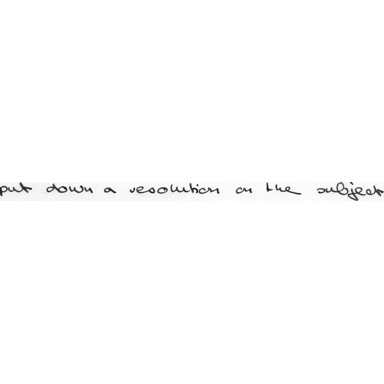

In [35]:
# Get one training sample
sample = ds["train"][0]

# Apply custom preprocessing
pixel_values, processed_image = preprocess_iam_image(
    sample["image"],
    processor
)

print("Original size:", sample["image"].size)
print("Processed size:", processed_image.size)
print("Tensor shape:", pixel_values.shape)

display(processed_image)

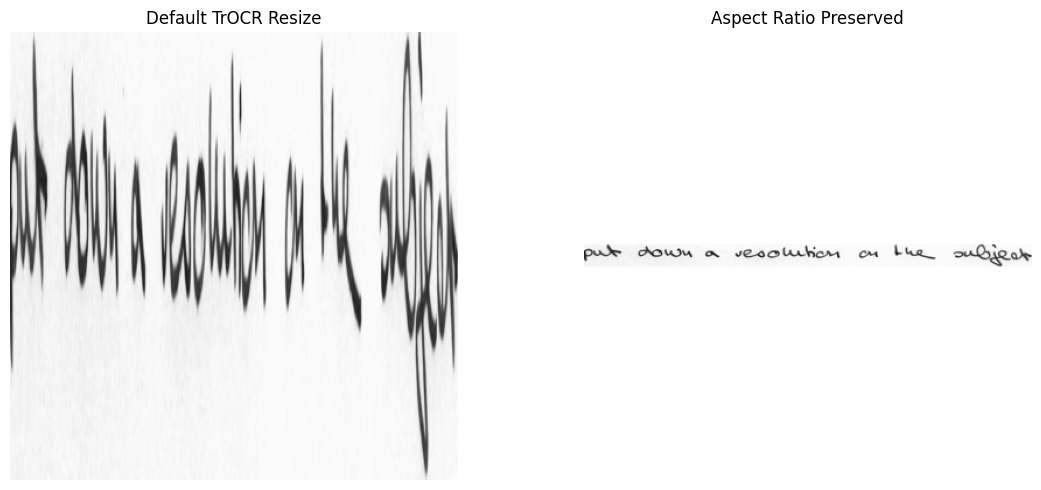

In [36]:
import matplotlib.pyplot as plt

sample = ds["train"][0]
image = sample["image"].convert("RGB")

# Default TrOCR preprocessing
default_pixels = processor(
    images=image,
    return_tensors="pt"
).pixel_values

# Convert normalized tensor back to image
default_image = (
    default_pixels[0].permute(1, 2, 0).numpy() * 0.5 + 0.5
).clip(0, 1)

# Aspect-ratio preserving preprocessing
_, preserved_image = preprocess_iam_image(
    image,
    processor
)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(default_image)
plt.title("Default TrOCR Resize")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preserved_image)
plt.title("Aspect Ratio Preserved")
plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
import torch
from torch.utils.data import Dataset, DataLoader

class TrOCRDataset(Dataset):
    def __init__(self, hf_split, processor):
        self.data = hf_split
        self.processor = processor

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        image = item["image"].convert("RGB")
        text = item["text"]

        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.squeeze(0)

        labels = self.processor.tokenizer(
            text,
            padding=False,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


def trocr_collate_fn(batch):
    pixel_values = torch.stack([
        item["pixel_values"] for item in batch
    ])

    labels = [
        item["labels"] for item in batch
    ]

    labels = torch.nn.utils.rnn.pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    return {
        "pixel_values": pixel_values,
        "labels": labels
    }


print("TrOCR Dataset class created successfully!")

TrOCR Dataset class created successfully!


In [38]:
from torch.utils.data import DataLoader

# Create training dataset
train_dataset = TrOCRDataset(
    ds["train"],
    processor
)

# Create a small DataLoader for testing
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=trocr_collate_fn,
    num_workers=0
)

# Get one batch
batch = next(iter(train_loader))

pixel_values = batch["pixel_values"]
labels = batch["labels"]

print("Pixel values shape:", pixel_values.shape)
print("Labels shape:", labels.shape)

print("Pixel values dtype:", pixel_values.dtype)
print("Labels dtype:", labels.dtype)

print("\nFirst sample text:")
first_labels = labels[0]
first_labels = first_labels[first_labels != -100]

decoded_text = processor.tokenizer.decode(
    first_labels,
    skip_special_tokens=True
)

print(decoded_text)

print("\nOriginal text:")
print(ds["train"][0]["text"])

Pixel values shape: torch.Size([2, 3, 384, 384])
Labels shape: torch.Size([2, 13])
Pixel values dtype: torch.float32
Labels dtype: torch.int64

First sample text:
as on bases - were decisively carried .

Original text:
put down a resolution on the subject


In [39]:
# Get the first dataset sample directly
sample = train_dataset[0]

# Decode its labels
decoded_text = processor.tokenizer.decode(
    sample["labels"],
    skip_special_tokens=True
)

print("Original text:")
print(ds["train"][0]["text"])

print("\nDecoded text:")
print(decoded_text)

print("\nMatch:", decoded_text == ds["train"][0]["text"])

Original text:
put down a resolution on the subject

Decoded text:
put down a resolution on the subject

Match: True


In [40]:
# Configure special tokens
trocr_model.config.decoder_start_token_id = (
    processor.tokenizer.cls_token_id
)

trocr_model.config.pad_token_id = (
    processor.tokenizer.pad_token_id
)

trocr_model.config.eos_token_id = (
    processor.tokenizer.eos_token_id
)

trocr_model.config.vocab_size = (
    trocr_model.config.decoder.vocab_size
)

# Configure generation settings
trocr_model.generation_config.decoder_start_token_id = (
    processor.tokenizer.cls_token_id
)

trocr_model.generation_config.pad_token_id = (
    processor.tokenizer.pad_token_id
)

trocr_model.generation_config.eos_token_id = (
    processor.tokenizer.eos_token_id
)

print("Decoder start token:",
      trocr_model.config.decoder_start_token_id)

print("Padding token:",
      trocr_model.config.pad_token_id)

print("EOS token:",
      trocr_model.config.eos_token_id)

print("Vocabulary size:",
      trocr_model.config.vocab_size)

print("Gradient checkpointing available:",
      hasattr(trocr_model, "gradient_checkpointing_enable"))

Decoder start token: 0
Padding token: 1
EOS token: 2
Vocabulary size: 50265
Gradient checkpointing available: True


In [41]:
# Disable cache during training
trocr_model.config.use_cache = False
trocr_model.config.decoder.use_cache = False

# Enable gradient checkpointing
trocr_model.gradient_checkpointing_enable()

# Enable training mode
trocr_model.train()

# Check trainable parameters
total_params = sum(
    p.numel() for p in trocr_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in trocr_model.parameters()
    if p.requires_grad
)

print("Gradient checkpointing enabled!")
print("Model training mode:", trocr_model.training)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Gradient checkpointing enabled!
Model training mode: True
Total parameters: 384,864,768
Trainable parameters: 384,864,768
GPU: Tesla T4
GPU memory allocated: 1.44 GB


In [43]:
import torch
import time

# Create a single-sample batch
test_batch = next(iter(DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=trocr_collate_fn,
    num_workers=0
)))

pixel_values = test_batch["pixel_values"].to(device)
labels = test_batch["labels"].to(device)

# Create a temporary optimizer
test_optimizer = torch.optim.AdamW(
    trocr_model.parameters(),
    lr=1e-5
)

# Enable training mode
trocr_model.train()
test_optimizer.zero_grad(set_to_none=True)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start_time = time.time()

try:
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = trocr_model(
            pixel_values=pixel_values,
            labels=labels
        )
        loss = outputs.loss

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        trocr_model.parameters(),
        max_norm=1.0
    )

    test_optimizer.step()

    elapsed = time.time() - start_time

    print("Training step successful!")
    print("Loss:", round(loss.item(), 4))
    print("Time:", round(elapsed, 2), "seconds")
    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            2
        ),
        "GB"
    )

except torch.cuda.OutOfMemoryError:
    print("CUDA Out of Memory!")
    torch.cuda.empty_cache()

finally:
    test_optimizer.zero_grad(set_to_none=True)
    del test_optimizer
    del outputs
    del loss
    del pixel_values
    del labels
    del test_batch
    torch.cuda.empty_cache()

NameError: name 'outputs' is not defined

In [44]:
# Inspect model parameters and buffers
meta_parameters = []

for name, param in trocr_model.named_parameters():
    if param.device.type == "meta":
        meta_parameters.append(name)

meta_buffers = []

for name, buffer in trocr_model.named_buffers():
    if buffer.device.type == "meta":
        meta_buffers.append(name)

print("Meta parameters:", len(meta_parameters))
print("Meta buffers:", len(meta_buffers))

print("\nMeta parameter names:")
for name in meta_parameters[:20]:
    print(name)

print("\nMeta buffer names:")
for name in meta_buffers[:20]:
    print(name)

print("\nDecoder positional embedding device:")

print(
    trocr_model.decoder.model.decoder
    .embed_positions.weight.device
)

print("\nModel device:", next(trocr_model.parameters()).device)

Meta parameters: 0
Meta buffers: 0

Meta parameter names:

Meta buffer names:

Decoder positional embedding device:


AttributeError: 'TrOCRSinusoidalPositionalEmbedding' object has no attribute 'weight'

In [45]:
import torch

# Get positional embedding module
pos_module = trocr_model.decoder.model.decoder.embed_positions

print("Module:")
print(pos_module)

print("\nModule class:")
print(type(pos_module))

print("\nModule device:")
for name, param in pos_module.named_parameters():
    print(name, param.device, param.shape)

for name, buffer in pos_module.named_buffers():
    print(name, buffer.device, buffer.shape)

print("\nInput embeddings device:")
print(
    trocr_model.decoder.model.decoder
    .embed_tokens.weight.device
)

print("\nDecoder device:")
print(next(trocr_model.decoder.parameters()).device)

# Test positional embedding directly
dummy_ids = torch.tensor([[0, 5, 10]], device=device)

try:
    pos_output = pos_module(dummy_ids)

    print("\nPositional embedding test: SUCCESS")
    print("Output shape:", pos_output.shape)
    print("Output device:", pos_output.device)

except Exception as e:
    print("\nPositional embedding test: FAILED")
    print(type(e).__name__, str(e))

Module:
TrOCRSinusoidalPositionalEmbedding()

Module class:
<class 'transformers.models.trocr.modeling_trocr.TrOCRSinusoidalPositionalEmbedding'>

Module device:

Input embeddings device:
cuda:0

Decoder device:
cuda:0

Positional embedding test: SUCCESS
Output shape: torch.Size([1, 3, 1024])
Output device: meta


In [46]:
pos_module = trocr_model.decoder.model.decoder.embed_positions

print("Module attributes:")

for name, value in vars(pos_module).items():
    if torch.is_tensor(value):
        print(name, value.device, value.shape)

print("\nRegistered buffers:")
for name, value in pos_module.named_buffers():
    print(name, value.device, value.shape)

print("\nState dict:")
for name, value in pos_module.state_dict().items():
    print(name, value.device, value.shape)

print("\nModule source:")
import inspect

print(inspect.getsource(type(pos_module).forward))

Module attributes:
weights meta torch.Size([1026, 1024])

Registered buffers:

State dict:

Module source:
    @torch.no_grad()
    def forward(self, input_ids: torch.Tensor, past_key_values_length: int = 0):
        bsz, seq_len = input_ids.size()
        # Create the position ids from the input token ids. Any padded tokens remain padded.
        position_ids = self.create_position_ids_from_input_ids(input_ids, self.padding_idx, past_key_values_length).to(
            input_ids.device
        )

        # expand embeddings if needed
        max_pos = self.padding_idx + 1 + seq_len
        if self.weights is None or max_pos > self.weights.size(0):
            # recompute/expand embeddings if needed
            self.weights = self.get_embedding(max_pos, self.embedding_dim, self.padding_idx)

        x = self.weights.index_select(0, position_ids.view(-1)).view(bsz, seq_len, -1).detach()

        return x



In [47]:
import inspect

pos_module = trocr_model.decoder.model.decoder.embed_positions

print("Embedding dimension:", pos_module.embedding_dim)
print("Padding index:", pos_module.padding_idx)
print("Current weights device:", pos_module.weights.device)

print("\nget_embedding signature:")
print(inspect.signature(pos_module.get_embedding))

Embedding dimension: 1024
Padding index: 1
Current weights device: meta

get_embedding signature:
(num_embeddings: int, embedding_dim: int, padding_idx: int | None = None)


In [48]:
# Get positional embedding module
pos_module = trocr_model.decoder.model.decoder.embed_positions

# Recreate positional embedding weights
with torch.no_grad():
    new_weights = pos_module.get_embedding(
        1026,
        1024,
        pos_module.padding_idx
    )

    pos_module.weights = new_weights.to(device)

print("Positional embeddings repaired!")

print("Weights shape:", pos_module.weights.shape)
print("Weights device:", pos_module.weights.device)
print("Is Meta:", pos_module.weights.is_meta)

Positional embeddings repaired!
Weights shape: torch.Size([1026, 1024])
Weights device: cuda:0
Is Meta: False


In [49]:
import torch
import time

# Prepare one training sample
test_batch = next(iter(DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=trocr_collate_fn,
    num_workers=0
)))

pixel_values = test_batch["pixel_values"].to(device)
labels = test_batch["labels"].to(device)

trocr_model.train()
trocr_model.zero_grad(set_to_none=True)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start_time = time.time()

outputs = None
loss = None

try:
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = trocr_model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss

    print("Forward pass successful!")
    print("Loss:", round(loss.item(), 4))

    loss.backward()

    print("Backward pass successful!")

    elapsed = time.time() - start_time

    print("Time:", round(elapsed, 2), "seconds")

    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            2
        ),
        "GB"
    )

except Exception as e:
    print("Training test failed!")
    print(type(e).__name__, str(e))

finally:
    trocr_model.zero_grad(set_to_none=True)

    del pixel_values, labels, test_batch

    if outputs is not None:
        del outputs

    if loss is not None:
        del loss

    torch.cuda.empty_cache()

Forward pass successful!
Loss: 8.6164
Backward pass successful!
Time: 0.65 seconds
Peak GPU memory: 3.0 GB


In [50]:
from torch.utils.data import DataLoader

# Create training and validation datasets
train_dataset = TrOCRDataset(ds["train"], processor)
val_dataset = TrOCRDataset(ds["validation"], processor)

# Training configuration
BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
EPOCHS = 10
LEARNING_RATE = 1e-5
MAX_GRAD_NORM = 1.0

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=trocr_collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=trocr_collate_fn,
    num_workers=0,
    pin_memory=True
)

print("TrOCR training configuration ready!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Batch size:", BATCH_SIZE)
print("Effective batch size:", BATCH_SIZE * GRADIENT_ACCUMULATION)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

TrOCR training configuration ready!
Training samples: 6482
Validation samples: 976
Batch size: 2
Effective batch size: 8
Epochs: 10
Learning rate: 1e-05
Training batches: 3241
Validation batches: 488


In [51]:

import torch
import time
import os
from tqdm.auto import tqdm

# Calculate edit distance
def edit_distance(a, b):
    dp = list(range(len(b) + 1))

    for i, char_a in enumerate(a, 1):
        new_dp = [i] + [0] * len(b)

        for j, char_b in enumerate(b, 1):
            new_dp[j] = min(
                new_dp[j - 1] + 1,
                dp[j] + 1,
                dp[j - 1] + (char_a != char_b)
            )

        dp = new_dp

    return dp[-1]


# Calculate CER and WER
def calculate_metrics(references, predictions):
    char_errors = 0
    total_chars = 0
    word_errors = 0
    total_words = 0

    for ref, pred in zip(references, predictions):
        ref = ref.strip()
        pred = pred.strip()

        char_errors += edit_distance(ref, pred)
        total_chars += len(ref)

        ref_words = ref.split()
        pred_words = pred.split()

        word_errors += edit_distance(ref_words, pred_words)
        total_words += len(ref_words)

    cer = char_errors / max(total_chars, 1)
    wer = word_errors / max(total_words, 1)

    return cer, wer


# Use one epoch for the first training test
EPOCHS = 1

optimizer = torch.optim.AdamW(
    trocr_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scaler = torch.amp.GradScaler("cuda")

best_val_cer = float("inf")
os.makedirs("checkpoints", exist_ok=True)

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # -------------------------
    # Training
    # -------------------------
    trocr_model.train()
    optimizer.zero_grad(set_to_none=True)

    total_train_loss = 0.0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for step, batch in enumerate(progress):
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        # Handle the final incomplete accumulation group
        group_start = (step // GRADIENT_ACCUMULATION) * GRADIENT_ACCUMULATION
        group_size = min(
            GRADIENT_ACCUMULATION,
            len(train_loader) - group_start
        )

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = trocr_model(
                pixel_values=pixel_values,
                labels=labels
            )
            loss = outputs.loss / group_size

        scaler.scale(loss).backward()

        total_train_loss += loss.item() * group_size

        is_update_step = (
            (step + 1) % GRADIENT_ACCUMULATION == 0
            or (step + 1) == len(train_loader)
        )

        if is_update_step:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                trocr_model.parameters(),
                MAX_GRAD_NORM
            )

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        progress.set_postfix(
            loss=f"{loss.item() * group_size:.4f}"
        )

        del pixel_values, labels, outputs, loss

    avg_train_loss = total_train_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    trocr_model.eval()

    references = []
    predictions = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"]

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                generated_ids = trocr_model.generate(
                    pixel_values=pixel_values,
                    max_new_tokens=128,
                    num_beams=1
                )

            pred_texts = processor.batch_decode(
                generated_ids,
                skip_special_tokens=True
            )

            labels = labels.clone()
            labels[labels == -100] = processor.tokenizer.pad_token_id

            ref_texts = processor.batch_decode(
                labels,
                skip_special_tokens=True
            )

            predictions.extend(pred_texts)
            references.extend(ref_texts)

            del pixel_values, generated_ids

    val_cer, val_wer = calculate_metrics(
        references,
        predictions
    )

    epoch_time = time.time() - epoch_start

    print(f"\nEpoch {epoch + 1} Results")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Validation CER: {val_cer:.4f}")
    print(f"Validation WER: {val_wer:.4f}")
    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")

    # Save best checkpoint
    if val_cer < best_val_cer:
        best_val_cer = val_cer

        torch.save(
            trocr_model.state_dict(),
            "checkpoints/trocr_best.pt"
        )

        processor.save_pretrained("checkpoints/trocr_processor")

        print("Best TrOCR checkpoint saved!")

    torch.cuda.empty_cache()

print("\nTraining experiment completed!")
print("Best Validation CER:", best_val_cer)


Epoch 1/1:   0%|          | 0/3241 [00:00<?, ?it/s]

Validation:   0%|          | 0/488 [00:00<?, ?it/s]


Epoch 1 Results
Train Loss: 0.7719
Validation CER: 0.6182
Validation WER: 0.6498
Epoch Time: 30.87 minutes
Best TrOCR checkpoint saved!

Training experiment completed!
Best Validation CER: 0.6181965109093502


In [52]:
trocr_model.eval()

sample_batch = next(iter(val_loader))
pixel_values = sample_batch["pixel_values"][:5].to(device)
labels = sample_batch["labels"][:5].clone()

with torch.no_grad():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        generated_ids = trocr_model.generate(
            pixel_values=pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

predictions = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)

labels[labels == -100] = processor.tokenizer.pad_token_id

references = processor.batch_decode(
    labels,
    skip_special_tokens=True
)

for i in range(len(predictions)):
    print(f"\nSample {i+1}")
    print("Original:  ", references[i])
    print("Predicted: ", predictions[i])

del sample_batch, pixel_values, labels, generated_ids
torch.cuda.empty_cache()


Sample 1
Original:   It was a splendid interpretation of the
Predicted:  

Sample 2
Original:   sympathetic C O . Paul Daneman gave another
Predicted:  sympathetic CO. Paul Baseman gave another


In [53]:
trocr_model.eval()

sample_batch = next(iter(val_loader))
pixel_values = sample_batch["pixel_values"][:20].to(device)
labels = sample_batch["labels"][:20].clone()

with torch.no_grad():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        generated_ids = trocr_model.generate(
            pixel_values=pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

predictions = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)

labels[labels == -100] = processor.tokenizer.pad_token_id

references = processor.batch_decode(
    labels,
    skip_special_tokens=True
)

empty_predictions = sum(
    1 for pred in predictions if not pred.strip()
)

print("Total samples:", len(predictions))
print("Empty predictions:", empty_predictions)

for i, (ref, pred) in enumerate(zip(references, predictions)):
    print(f"\nSample {i+1}")
    print("Original: ", ref)
    print("Predicted:", pred if pred.strip() else "[EMPTY]")

del sample_batch, pixel_values, labels, generated_ids
torch.cuda.empty_cache()

Total samples: 2
Empty predictions: 1

Sample 1
Original:  It was a splendid interpretation of the
Predicted: [EMPTY]

Sample 2
Original:  sympathetic C O . Paul Daneman gave another
Predicted: sympathetic CO. Paul Baseman gave another


In [54]:
trocr_model.eval()

references = []
predictions = []

with torch.no_grad():
    for batch_idx, batch in enumerate(val_loader):

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].clone()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            generated_ids = trocr_model.generate(
                pixel_values=pixel_values,
                max_new_tokens=128,
                num_beams=1
            )

        pred_texts = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        labels[labels == -100] = processor.tokenizer.pad_token_id

        ref_texts = processor.batch_decode(
            labels,
            skip_special_tokens=True
        )

        predictions.extend(pred_texts)
        references.extend(ref_texts)

        del pixel_values, labels, generated_ids

        if len(predictions) >= 20:
            break

torch.cuda.empty_cache()

empty_count = sum(1 for p in predictions if not p.strip())

print("Total samples:", len(predictions))
print("Empty predictions:", empty_count)

for i, (ref, pred) in enumerate(zip(references, predictions)):
    print(f"\nSample {i+1}")
    print("Original: ", ref)
    print("Predicted:", pred if pred.strip() else "[EMPTY]")

Total samples: 20
Empty predictions: 14

Sample 1
Original:  It was a splendid interpretation of the
Predicted: [EMPTY]

Sample 2
Original:  sympathetic C O . Paul Daneman gave another
Predicted: sympathetic CO. Paul Baseman gave another

Sample 3
Original:  part . The rest of the cast were well chosen ,
Predicted: past . The suit of the past worse well chosen ,

Sample 4
Original:  with James Maxwell making a fine job of the
Predicted: [EMPTY]

Sample 5
Original:  " The Little Key . "
Predicted: [EMPTY]

Sample 6
Original:  first-class performance last night as a
Predicted: first-class performance last as a

Sample 7
Original:  wartime naval officer in the B B C's
Predicted: [EMPTY]

Sample 8
Original:  the imagination which asked the viewer to
Predicted: [EMPTY]

Sample 9
Original:  " Britain - Blood , Sweat , and Tears ... Plus
Predicted: [EMPTY]

Sample 10
Original:  The play was no more than a figment of
Predicted: [EMPTY]

Sample 11
Original:  effect . MORE than 100 viewers compl

In [55]:
print("Tokenizer special tokens:")
print("BOS token:", processor.tokenizer.bos_token)
print("BOS ID:", processor.tokenizer.bos_token_id)

print("EOS token:", processor.tokenizer.eos_token)
print("EOS ID:", processor.tokenizer.eos_token_id)

print("PAD token:", processor.tokenizer.pad_token)
print("PAD ID:", processor.tokenizer.pad_token_id)

print("\nModel configuration:")
print("Decoder start ID:", trocr_model.config.decoder_start_token_id)
print("Generation start ID:", trocr_model.generation_config.decoder_start_token_id)

Tokenizer special tokens:
BOS token: <s>
BOS ID: 0
EOS token: </s>
EOS ID: 2
PAD token: <pad>
PAD ID: 1

Model configuration:
Decoder start ID: 0
Generation start ID: 0


In [56]:
print("Decoder configuration:")
print("Decoder start token:", trocr_model.config.decoder_start_token_id)
print("Decoder BOS token:", trocr_model.config.decoder.bos_token_id)
print("Decoder EOS token:", trocr_model.config.decoder.eos_token_id)
print("Decoder PAD token:", trocr_model.config.decoder.pad_token_id)

print("\nGeneration configuration:")
print("Generation BOS:", trocr_model.generation_config.bos_token_id)
print("Generation EOS:", trocr_model.generation_config.eos_token_id)
print("Generation PAD:", trocr_model.generation_config.pad_token_id)

print("\nGeneration settings:")
print("Max length:", trocr_model.generation_config.max_length)
print("Forced EOS:", trocr_model.generation_config.forced_eos_token_id)

Decoder configuration:
Decoder start token: 0
Decoder BOS token: 0
Decoder EOS token: 2
Decoder PAD token: 1

Generation configuration:
Generation BOS: 0
Generation EOS: 2
Generation PAD: 1

Generation settings:
Max length: None
Forced EOS: None


In [57]:
trocr_model.eval()

batch = next(iter(val_loader))
pixel_values = batch["pixel_values"][:2].to(device)

with torch.no_grad():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        generated_ids = trocr_model.generate(
            pixel_values=pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

for i, ids in enumerate(generated_ids):
    print(f"\nSample {i+1}")
    print("Token IDs:", ids[:20].tolist())

    print(
        "Decoded with special tokens:",
        processor.tokenizer.decode(
            ids,
            skip_special_tokens=False
        )
    )

    print(
        "Decoded without special tokens:",
        processor.tokenizer.decode(
            ids,
            skip_special_tokens=True
        )
    )

del batch, pixel_values, generated_ids
torch.cuda.empty_cache()


Sample 1
Token IDs: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded with special tokens: <s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s><s>
Decoded without special tokens: 

Sample 2
Token IDs: [0, 8628, 6195, 41658, 6247, 4, 1206, 7093, 5649, 851, 277, 2, 1, 1, 1, 1, 1, 1, 1, 1]
Decoded with special tokens: <s>sympathetic CO. Paul Baseman gave another</s><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pa

In [58]:
sample = train_dataset[0]

print("Original text:")
print(ds["train"][0]["text"])

print("\nLabel token IDs:")
print(sample["labels"][:20].tolist())

print("\nDecoded labels:")
print(
    processor.tokenizer.decode(
        sample["labels"],
        skip_special_tokens=False
    )
)

print("\nFirst label token:")
print(processor.tokenizer.convert_ids_to_tokens(
    sample["labels"][0].item()
))

Original text:
put down a resolution on the subject

Label token IDs:
[0, 9179, 159, 10, 3547, 15, 5, 2087, 2]

Decoded labels:
<s>put down a resolution on the subject</s>

First label token:
<s>


In [59]:
trocr_model.eval()

batch = next(iter(val_loader))
pixel_values = batch["pixel_values"][:2].to(device)

original_start = trocr_model.generation_config.decoder_start_token_id

for start_id in [original_start, processor.tokenizer.eos_token_id]:

    print("\nDecoder start ID:", start_id)

    with torch.no_grad():
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            generated_ids = trocr_model.generate(
                pixel_values=pixel_values,
                max_new_tokens=64,
                num_beams=1,
                decoder_start_token_id=start_id
            )

    for i, text in enumerate(
        processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )
    ):
        print(f"Sample {i+1}:", text if text.strip() else "[EMPTY]")

    del generated_ids

# Restore original setting
trocr_model.generation_config.decoder_start_token_id = original_start

del batch, pixel_values
torch.cuda.empty_cache()


Decoder start ID: 0
Sample 1: [EMPTY]
Sample 2: sympathetic CO. Paul Baseman gave another

Decoder start ID: 2
Sample 1: [EMPTY]
Sample 2: sympathetic CO . Paul Basemann gave another


In [60]:
import torch

trocr_model.eval()

batch = next(iter(val_loader))
pixel_values = batch["pixel_values"][:2].to(device)

start_ids = torch.full(
    (2, 1),
    processor.tokenizer.bos_token_id,
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = trocr_model(
            pixel_values=pixel_values,
            decoder_input_ids=start_ids
        )

        logits = outputs.logits[:, -1, :].float()
        probabilities = torch.softmax(logits, dim=-1)

for i in range(2):
    values, indices = torch.topk(probabilities[i], k=10)

    print(f"\nSample {i+1} - Top 10 next tokens:")

    for token_id, probability in zip(indices.tolist(), values.tolist()):
        token = processor.tokenizer.decode([token_id])
        print(
            f"ID: {token_id:5d} | "
            f"Token: {repr(token):20s} | "
            f"Probability: {probability:.4f}"
        )

del batch, pixel_values, start_ids, outputs, logits, probabilities
torch.cuda.empty_cache()


Sample 1 - Top 10 next tokens:
ID:     0 | Token: '<s>'                | Probability: 0.6702
ID:   243 | Token: 'It'                 | Probability: 0.2772
ID:  1106 | Token: 'If'                 | Probability: 0.0173
ID:   108 | Token: "'"                  | Probability: 0.0043
ID:   113 | Token: '"'                  | Probability: 0.0042
ID:   405 | Token: 'it'                 | Probability: 0.0039
ID:   133 | Token: 'The'                | Probability: 0.0025
ID:  1594 | Token: 'if'                 | Probability: 0.0025
ID:  3750 | Token: 'At'                 | Probability: 0.0018
ID:   894 | Token: 'He'                 | Probability: 0.0017

Sample 2 - Top 10 next tokens:
ID:  8628 | Token: 'sy'                 | Probability: 0.6726
ID:     0 | Token: '<s>'                | Probability: 0.2826
ID: 45266 | Token: 'sym'                | Probability: 0.0171
ID:    29 | Token: 's'                  | Probability: 0.0059
ID: 38972 | Token: 'syn'                | Probability: 0.0046
ID: 16

In [61]:
class TrOCRDataset(Dataset):
    def __init__(self, hf_split, processor):
        self.data = hf_split
        self.processor = processor

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        image = item["image"].convert("RGB")
        text = item["text"]

        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        ).pixel_values.squeeze(0)

        # Tokenize without BOS and append EOS
        token_ids = self.processor.tokenizer(
            text,
            add_special_tokens=False,
            truncation=True,
            max_length=127
        ).input_ids

        token_ids = token_ids + [
            self.processor.tokenizer.eos_token_id
        ]

        labels = torch.tensor(token_ids, dtype=torch.long)

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


# Recreate datasets using corrected labels
train_dataset = TrOCRDataset(ds["train"], processor)
val_dataset = TrOCRDataset(ds["validation"], processor)

print("Corrected TrOCR datasets created!")

Corrected TrOCR datasets created!


In [62]:
sample = train_dataset[0]

print("Original text:")
print(ds["train"][0]["text"])

print("\nCorrected label IDs:")
print(sample["labels"].tolist())

print("\nDecoded labels:")
print(
    processor.tokenizer.decode(
        sample["labels"],
        skip_special_tokens=False
    )
)

print("\nFirst token:")
print(
    processor.tokenizer.convert_ids_to_tokens(
        sample["labels"][0].item()
    )
)

Original text:
put down a resolution on the subject

Corrected label IDs:
[9179, 159, 10, 3547, 15, 5, 2087, 2]

Decoded labels:
put down a resolution on the subject</s>

First token:
put


In [63]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=trocr_collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=trocr_collate_fn,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders recreated successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

DataLoaders recreated successfully!
Training batches: 3241
Validation batches: 488


In [64]:
print("Model exists:", "trocr_model" in globals())

if "trocr_model" in globals():
    print("Model device:", next(trocr_model.parameters()).device)
    print("Model training mode:", trocr_model.training)
    print(
        "Model parameters:",
        sum(p.numel() for p in trocr_model.parameters())
    )

print("Original checkpoint:", "microsoft/trocr-base-stage1")

Model exists: True
Model device: cuda:0
Model training mode: False
Model parameters: 384864768
Original checkpoint: microsoft/trocr-base-stage1


In [65]:
import gc
import torch
from transformers import VisionEncoderDecoderModel

# Release the previous fine-tuned model
del trocr_model
gc.collect()
torch.cuda.empty_cache()

# Load the original pretrained model
print("Loading original TrOCR model...")

trocr_model = VisionEncoderDecoderModel.from_pretrained(
    "microsoft/trocr-base-stage1"
).to(device)

# Repair positional embeddings if they are on the meta device
pos_module = trocr_model.decoder.model.decoder.embed_positions

if pos_module.weights.is_meta:
    with torch.no_grad():
        new_weights = pos_module.get_embedding(
            1026,
            1024,
            pos_module.padding_idx
        )
        pos_module.weights = new_weights.to(device)

# Configure special tokens
trocr_model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
trocr_model.config.pad_token_id = processor.tokenizer.pad_token_id
trocr_model.config.eos_token_id = processor.tokenizer.eos_token_id
trocr_model.config.vocab_size = trocr_model.config.decoder.vocab_size

trocr_model.generation_config.decoder_start_token_id = processor.tokenizer.cls_token_id
trocr_model.generation_config.pad_token_id = processor.tokenizer.pad_token_id
trocr_model.generation_config.eos_token_id = processor.tokenizer.eos_token_id

# Enable training optimizations
trocr_model.config.use_cache = False
trocr_model.config.decoder.use_cache = False
trocr_model.gradient_checkpointing_enable()

print("Original TrOCR model loaded successfully!")
print("Device:", next(trocr_model.parameters()).device)
print("Parameters:", sum(p.numel() for p in trocr_model.parameters()))
print("Positional embeddings on meta:", pos_module.weights.is_meta)

Loading original TrOCR model...


Loading weights:   0%|          | 0/476 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-stage1
Key                                                 | Status     | 
----------------------------------------------------+------------+-
decoder.model.decoder.embed_positions._float_tensor | UNEXPECTED | 
encoder.pooler.dense.weight                         | MISSING    | 
encoder.pooler.dense.bias                           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Original TrOCR model loaded successfully!
Device: cuda:0
Parameters: 384864768
Positional embeddings on meta: False


In [66]:
import torch

trocr_model.train()
trocr_model.config.use_cache = False
trocr_model.config.decoder.use_cache = False

# Get one training batch
batch = next(iter(train_loader))

pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

# Forward pass
trocr_model.zero_grad(set_to_none=True)

with torch.autocast(device_type="cuda", dtype=torch.float16):
    outputs = trocr_model(
        pixel_values=pixel_values,
        labels=labels
    )
    loss = outputs.loss

print("Pixel values shape:", pixel_values.shape)
print("Labels shape:", labels.shape)
print("Loss:", loss.item())

# Backward pass
loss.backward()

print("Backward pass successful!")

trocr_model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

Pixel values shape: torch.Size([2, 3, 384, 384])
Labels shape: torch.Size([2, 15])
Loss: 8.821876525878906
Backward pass successful!


In [67]:
import torch
from torch.optim import AdamW
from torch.amp import GradScaler

# Training configuration
EPOCHS = 1
LEARNING_RATE = 1e-5
GRADIENT_ACCUMULATION = 4
MAX_GRAD_NORM = 1.0

# Optimizer
optimizer = AdamW(
    trocr_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# Mixed precision scaler
scaler = GradScaler("cuda")

# Reset gradients
optimizer.zero_grad(set_to_none=True)

print("Corrected TrOCR training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Effective batch size:", BATCH_SIZE * GRADIENT_ACCUMULATION)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Corrected TrOCR training configuration ready!
Epochs: 1
Learning rate: 1e-05
Batch size: 2
Effective batch size: 8
Training batches: 3241
Validation batches: 488


In [68]:
import time
from tqdm.auto import tqdm
import torch

trocr_model.train()
epoch_start = time.time()

total_loss = 0.0
optimizer.zero_grad(set_to_none=True)

progress_bar = tqdm(train_loader, desc="TrOCR Training")

for step, batch in enumerate(progress_bar):

    pixel_values = batch["pixel_values"].to(device)
    labels = batch["labels"].to(device)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = trocr_model(
            pixel_values=pixel_values,
            labels=labels
        )
        loss = outputs.loss
        scaled_loss = loss / GRADIENT_ACCUMULATION

    scaler.scale(scaled_loss).backward()

    if (step + 1) % GRADIENT_ACCUMULATION == 0 or (step + 1) == len(train_loader):
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            trocr_model.parameters(),
            MAX_GRAD_NORM
        )

        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

    total_loss += loss.item()
    progress_bar.set_postfix(loss=f"{loss.item():.4f}")

train_loss = total_loss / len(train_loader)
epoch_time = time.time() - epoch_start

print("Training completed!")
print("Average Training Loss:", round(train_loss, 4))
print("Epoch Time:", round(epoch_time / 60, 2), "minutes")

# Save the corrected training checkpoint separately
torch.save(
    trocr_model.state_dict(),
    "checkpoints/trocr_corrected_epoch1.pt"
)

print("Checkpoint saved: trocr_corrected_epoch1.pt")

TrOCR Training:   0%|          | 0/3241 [00:00<?, ?it/s]

Training completed!
Average Training Loss: 0.6179
Epoch Time: 13.5 minutes
Checkpoint saved: trocr_corrected_epoch1.pt


In [70]:
from tqdm.auto import tqdm
import torch
import evaluate

cer_metric = evaluate.load("cer")
wer_metric = evaluate.load("wer")

trocr_model.eval()

predictions = []
references = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="TrOCR Validation"):

        pixel_values = batch["pixel_values"].to(device)

        generated_ids = trocr_model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

        preds = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        refs = batch["labels"].clone()
        refs[refs == -100] = processor.tokenizer.pad_token_id

        targets = processor.batch_decode(
            refs,
            skip_special_tokens=True
        )

        predictions.extend(preds)
        references.extend(targets)

val_cer = cer_metric.compute(
    predictions=predictions,
    references=references
)

val_wer = wer_metric.compute(
    predictions=predictions,
    references=references
)

print("TrOCR Validation Results")
print("CER:", round(val_cer, 4))
print("WER:", round(val_wer, 4))
print("Samples:", len(predictions))

ModuleNotFoundError: No module named 'evaluate'

In [71]:
!pip install jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 61.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jiwer]


In [72]:
from tqdm.auto import tqdm
import torch
from jiwer import cer, wer

trocr_model.eval()

predictions = []
references = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="TrOCR Validation"):

        pixel_values = batch["pixel_values"].to(device)

        generated_ids = trocr_model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

        preds = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        refs = batch["labels"].clone()
        refs[refs == -100] = processor.tokenizer.pad_token_id

        targets = processor.batch_decode(
            refs,
            skip_special_tokens=True
        )

        predictions.extend(preds)
        references.extend(targets)

val_cer = cer(references, predictions)
val_wer = wer(references, predictions)

print("\nTrOCR Validation Results")
print("CER:", round(val_cer, 4))
print("WER:", round(val_wer, 4))
print("Samples:", len(predictions))

print("\nSample Predictions:")
for i in range(5):
    print("\nOriginal:", references[i])
    print("Predicted:", predictions[i])

TrOCR Validation:   0%|          | 0/488 [00:00<?, ?it/s]


TrOCR Validation Results
CER: 0.0577
WER: 0.1315
Samples: 976

Sample Predictions:

Original: It was a splendid interpretation of the
Predicted: It was a splendid interpretation of that

Original: sympathetic C O . Paul Daneman gave another
Predicted: sympathetic C.O. Paul Zimmerman gave another

Original: part . The rest of the cast were well chosen ,
Predicted: past . ' The suit of the cast more well chosen ,

Original: with James Maxwell making a fine job of the
Predicted: with farms discernell making a fine job of the

Original: " The Little Key . "
Predicted: " The little they " . "


In [73]:
import json
import os

os.makedirs("experiments", exist_ok=True)

trocr_results = {
    "model": "TrOCR-base-stage1",
    "epoch": 1,
    "train_loss": 0.6179,
    "validation_cer": val_cer,
    "validation_wer": val_wer,
    "training_time_minutes": 13.5,
    "training_samples": 6482,
    "validation_samples": 976,
    "batch_size": 2,
    "effective_batch_size": 8,
    "learning_rate": 1e-5,
    "gpu": "NVIDIA Tesla T4"
}

with open("experiments/trocr_corrected_seed0.json", "w") as f:
    json.dump(trocr_results, f, indent=4)

print("TrOCR experiment results saved successfully!")

TrOCR experiment results saved successfully!


In [74]:
import time
import torch
from tqdm.auto import tqdm

trocr_model.train()
epoch_start = time.time()

total_loss = 0.0
optimizer.zero_grad(set_to_none=True)

progress_bar = tqdm(train_loader, desc="TrOCR Epoch 2")

for step, batch in enumerate(progress_bar):

    pixel_values = batch["pixel_values"].to(device)
    labels = batch["labels"].to(device)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = trocr_model(
            pixel_values=pixel_values,
            labels=labels
        )
        loss = outputs.loss
        scaled_loss = loss / GRADIENT_ACCUMULATION

    scaler.scale(scaled_loss).backward()

    if (step + 1) % GRADIENT_ACCUMULATION == 0 or (step + 1) == len(train_loader):

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            trocr_model.parameters(),
            MAX_GRAD_NORM
        )

        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

    total_loss += loss.item()

    progress_bar.set_postfix(
        loss=f"{loss.item():.4f}"
    )

train_loss_epoch2 = total_loss / len(train_loader)
epoch_time = time.time() - epoch_start

print("Epoch 2 completed!")
print("Average Training Loss:", round(train_loss_epoch2, 4))
print("Epoch Time:", round(epoch_time / 60, 2), "minutes")

torch.save(
    trocr_model.state_dict(),
    "checkpoints/trocr_corrected_epoch2.pt"
)

print("Epoch 2 checkpoint saved successfully!")

TrOCR Epoch 2:   0%|          | 0/3241 [00:00<?, ?it/s]

Epoch 2 completed!
Average Training Loss: 0.2928
Epoch Time: 13.49 minutes
Epoch 2 checkpoint saved successfully!


In [75]:
from tqdm.auto import tqdm
import torch
from jiwer import cer, wer

trocr_model.eval()

predictions = []
references = []

with torch.no_grad():
    for batch in tqdm(val_loader, desc="TrOCR Epoch 2 Validation"):

        pixel_values = batch["pixel_values"].to(device)

        generated_ids = trocr_model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

        preds = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        refs = batch["labels"].clone()
        refs[refs == -100] = processor.tokenizer.pad_token_id

        targets = processor.batch_decode(
            refs,
            skip_special_tokens=True
        )

        predictions.extend(preds)
        references.extend(targets)

val_cer_epoch2 = cer(references, predictions)
val_wer_epoch2 = wer(references, predictions)

print("Epoch 2 Validation Results")
print("CER:", round(val_cer_epoch2, 4))
print("WER:", round(val_wer_epoch2, 4))
print("Samples:", len(predictions))

TrOCR Epoch 2 Validation:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 2 Validation Results
CER: 0.0653
WER: 0.1479
Samples: 976


In [76]:
import json
import shutil

# Save Epoch 1 as the current best checkpoint
shutil.copy2(
    "checkpoints/trocr_corrected_epoch1.pt",
    "checkpoints/trocr_best.pt"
)

history = {
    "epoch_1": {
        "train_loss": 0.6179,
        "val_cer": 0.0577,
        "val_wer": 0.1315
    },
    "epoch_2": {
        "train_loss": 0.2928,
        "val_cer": 0.0653,
        "val_wer": 0.1479
    },
    "best_epoch": 1,
    "best_val_cer": 0.0577
}

with open("experiments/trocr_history.json", "w") as f:
    json.dump(history, f, indent=4)

print("Training history saved!")
print("Best checkpoint: trocr_best.pt")
print("Best epoch: 1")
print("Best validation CER: 0.0577")

Training history saved!
Best checkpoint: trocr_best.pt
Best epoch: 1
Best validation CER: 0.0577


In [77]:
from torch.optim import AdamW

LEARNING_RATE = 5e-6

optimizer = AdamW(
    trocr_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

optimizer.zero_grad(set_to_none=True)

print("Epoch 3 optimizer ready!")
print("Learning Rate:", LEARNING_RATE)
print("Starting from Epoch 2 weights.")

Epoch 3 optimizer ready!
Learning Rate: 5e-06
Starting from Epoch 2 weights.


In [78]:
import time
import torch
from tqdm.auto import tqdm

trocr_model.train()
epoch_start = time.time()

total_loss = 0.0
optimizer.zero_grad(set_to_none=True)

progress_bar = tqdm(train_loader, desc="TrOCR Epoch 3")

for step, batch in enumerate(progress_bar):

    pixel_values = batch["pixel_values"].to(device)
    labels = batch["labels"].to(device)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = trocr_model(
            pixel_values=pixel_values,
            labels=labels
        )
        loss = outputs.loss
        scaled_loss = loss / GRADIENT_ACCUMULATION

    scaler.scale(scaled_loss).backward()

    if (step + 1) % GRADIENT_ACCUMULATION == 0 or (step + 1) == len(train_loader):

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            trocr_model.parameters(),
            MAX_GRAD_NORM
        )

        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

    total_loss += loss.item()

    progress_bar.set_postfix(
        loss=f"{loss.item():.4f}"
    )

train_loss_epoch3 = total_loss / len(train_loader)
epoch_time = time.time() - epoch_start

print("Epoch 3 completed!")
print("Average Training Loss:", round(train_loss_epoch3, 4))
print("Epoch Time:", round(epoch_time / 60, 2), "minutes")

torch.save(
    trocr_model.state_dict(),
    "checkpoints/trocr_corrected_epoch3.pt"
)

print("Epoch 3 checkpoint saved successfully!")

TrOCR Epoch 3:   0%|          | 0/3241 [00:00<?, ?it/s]

Epoch 3 completed!
Average Training Loss: 0.1263
Epoch Time: 13.44 minutes
Epoch 3 checkpoint saved successfully!


In [79]:
import torch
from tqdm.auto import tqdm
from jiwer import cer, wer

trocr_model.eval()

all_predictions = []
all_references = []

with torch.no_grad():

    for batch in tqdm(val_loader, desc="TrOCR Epoch 3 Validation"):

        pixel_values = batch["pixel_values"].to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            generated_ids = trocr_model.generate(
                pixel_values,
                max_new_tokens=128
            )

        predictions = processor.batch_decode(
            generated_ids,
            skip_special_tokens=True
        )

        references = processor.batch_decode(
            batch["labels"].masked_fill(
                batch["labels"] == -100,
                processor.tokenizer.pad_token_id
            ),
            skip_special_tokens=True
        )

        all_predictions.extend(predictions)
        all_references.extend(references)

val_cer_epoch3 = cer(all_references, all_predictions)
val_wer_epoch3 = wer(all_references, all_predictions)

print("Epoch 3 Validation Results")
print("Validation CER:", round(val_cer_epoch3, 4))
print("Validation WER:", round(val_wer_epoch3, 4))
print("Validation Samples:", len(all_references))

TrOCR Epoch 3 Validation:   0%|          | 0/488 [00:00<?, ?it/s]

Epoch 3 Validation Results
Validation CER: 0.0486
Validation WER: 0.114
Validation Samples: 976


In [80]:
import torch
import json
import os
import shutil

# Save the best model checkpoint
torch.save(
    trocr_model.state_dict(),
    "checkpoints/trocr_best.pt"
)

# Save epoch 3 checkpoint as best model
shutil.copy2(
    "checkpoints/trocr_corrected_epoch3.pt",
    "checkpoints/trocr_best.pt"
)

# Update experiment history
history_path = "experiments/trocr_history.json"

with open(history_path, "r") as f:
    history = json.load(f)

history["epoch_3"] = {
    "train_loss": round(train_loss_epoch3, 4),
    "val_cer": val_cer_epoch3,
    "val_wer": val_wer_epoch3
}

history["best_epoch"] = 3
history["best_val_cer"] = val_cer_epoch3
history["best_val_wer"] = val_wer_epoch3

with open(history_path, "w") as f:
    json.dump(history, f, indent=4)

print("Best TrOCR checkpoint updated!")
print("Best Epoch: 3")
print("Best Validation CER:", round(val_cer_epoch3, 4))
print("Best Validation WER:", round(val_wer_epoch3, 4))

Best TrOCR checkpoint updated!
Best Epoch: 3
Best Validation CER: 0.0486
Best Validation WER: 0.114


In [82]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Training configuration
LEARNING_RATE = 5e-6
PATIENCE = 2
MIN_LR = 1e-7
WEIGHT_DECAY = 0.01

# Reinitialize optimizer while keeping Epoch 3 model weights
optimizer = AdamW(
    trocr_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler
scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=MIN_LR
)

# Early stopping configuration
best_val_cer = 0.0486
best_epoch = 3
epochs_without_improvement = 0

print("Training configuration ready!")
print("Starting from Epoch 3")
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Best Validation CER:", best_val_cer)

Training configuration ready!
Starting from Epoch 3
Learning Rate: 5e-06
Best Validation CER: 0.0486


In [83]:
import time
import torch
import shutil
from tqdm.auto import tqdm
from jiwer import cer, wer

for epoch in range(4, 6):

    print(f"\n{'='*50}")
    print(f"Starting Epoch {epoch}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']}")
    print(f"{'='*50}")

    # Training
    trocr_model.train()
    epoch_start = time.time()
    total_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    progress_bar = tqdm(
        train_loader,
        desc=f"TrOCR Epoch {epoch}"
    )

    for step, batch in enumerate(progress_bar):

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = trocr_model(
                pixel_values=pixel_values,
                labels=labels
            )
            loss = outputs.loss
            scaled_loss = loss / GRADIENT_ACCUMULATION

        scaler.scale(scaled_loss).backward()

        if (step + 1) % GRADIENT_ACCUMULATION == 0 or (step + 1) == len(train_loader):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                trocr_model.parameters(),
                MAX_GRAD_NORM
            )

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = total_loss / len(train_loader)
    training_time = (time.time() - epoch_start) / 60

    print(f"\nEpoch {epoch} Training Loss: {train_loss:.4f}")
    print(f"Training Time: {training_time:.2f} minutes")

    # Validation
    trocr_model.eval()
    all_predictions = []
    all_references = []

    with torch.no_grad():

        for batch in tqdm(val_loader, desc=f"Validation Epoch {epoch}"):

            pixel_values = batch["pixel_values"].to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                generated_ids = trocr_model.generate(
                    pixel_values,
                    max_new_tokens=128
                )

            predictions = processor.batch_decode(
                generated_ids,
                skip_special_tokens=True
            )

            references = processor.batch_decode(
                batch["labels"].masked_fill(
                    batch["labels"] == -100,
                    processor.tokenizer.pad_token_id
                ),
                skip_special_tokens=True
            )

            all_predictions.extend(predictions)
            all_references.extend(references)

    val_cer = cer(all_references, all_predictions)
    val_wer = wer(all_references, all_predictions)

    print(f"\nEpoch {epoch} Validation CER: {val_cer:.4f}")
    print(f"Epoch {epoch} Validation WER: {val_wer:.4f}")

    # Update scheduler
    scheduler.step(val_cer)

    print("Updated Learning Rate:", optimizer.param_groups[0]["lr"])

    # Save epoch checkpoint
    torch.save(
        trocr_model.state_dict(),
        f"checkpoints/trocr_corrected_epoch{epoch}.pt"
    )

    # Save best checkpoint
    if val_cer < best_val_cer:

        best_val_cer = val_cer
        best_epoch = epoch
        epochs_without_improvement = 0

        shutil.copy2(
            f"checkpoints/trocr_corrected_epoch{epoch}.pt",
            "checkpoints/trocr_best.pt"
        )

        print("New best checkpoint saved!")

    else:
        epochs_without_improvement += 1
        print("No validation improvement.")

    print("Best Epoch:", best_epoch)
    print("Best Validation CER:", round(best_val_cer, 4))

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered!")
        break

print("\nTraining finished!")
print("Best Epoch:", best_epoch)
print("Best Validation CER:", round(best_val_cer, 4))


Starting Epoch 4
Learning Rate: 5e-06


TrOCR Epoch 4:   0%|          | 0/3241 [00:00<?, ?it/s]


Epoch 4 Training Loss: 0.0721
Training Time: 13.46 minutes


Validation Epoch 4:   0%|          | 0/488 [00:00<?, ?it/s]


Epoch 4 Validation CER: 0.0508
Epoch 4 Validation WER: 0.1200
Updated Learning Rate: 5e-06
No validation improvement.
Best Epoch: 3
Best Validation CER: 0.0486

Starting Epoch 5
Learning Rate: 5e-06


TrOCR Epoch 5:   0%|          | 0/3241 [00:00<?, ?it/s]


Epoch 5 Training Loss: 0.0450
Training Time: 13.44 minutes


Validation Epoch 5:   0%|          | 0/488 [00:00<?, ?it/s]


Epoch 5 Validation CER: 0.0505
Epoch 5 Validation WER: 0.1171
Updated Learning Rate: 5e-06
No validation improvement.
Best Epoch: 3
Best Validation CER: 0.0486
Early stopping triggered!

Training finished!
Best Epoch: 3
Best Validation CER: 0.0486


In [84]:
%cd /kaggle/working/proj

%%writefile src/models/attention.py

import torch
import torch.nn as nn


class CRNNBiLSTMAttention(nn.Module):

    def __init__(self, num_classes, hidden_size=128, num_heads=4):
        super().__init__()

        # CNN Feature Extractor
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )

        # Bidirectional LSTM
        self.rnn = nn.LSTM(
            input_size=64 * 16,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )

        # Self-Attention
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_size * 2,
            num_heads=num_heads,
            batch_first=True
        )

        self.layer_norm = nn.LayerNorm(hidden_size * 2)

        # Output Classifier
        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        # CNN
        features = self.cnn(x)

        # Convert CNN features to sequence
        features = features.permute(0, 3, 1, 2)

        batch_size, width, channels, height = features.shape

        features = features.reshape(
            batch_size,
            width,
            channels * height
        )

        # BiLSTM
        sequence, _ = self.rnn(features)

        # Self-Attention
        attended, _ = self.attention(
            sequence,
            sequence,
            sequence,
            need_weights=False
        )

        # Residual Connection + Normalization
        sequence = self.layer_norm(sequence + attended)

        # Classification
        output = self.classifier(sequence)

        output = output.log_softmax(dim=2)

        return output.permute(1, 0, 2)


def output_lengths(widths):
    return widths // 4


if __name__ == "__main__":

    model = CRNNBiLSTMAttention(num_classes=80).cuda()

    dummy_input = torch.randn(2, 1, 64, 400).cuda()

    output = model(dummy_input)

    print("Input shape:", dummy_input.shape)
    print("Output shape:", output.shape)

    print(
        "Parameters:",
        sum(p.numel() for p in model.parameters())
    )

/kaggle/working/proj


UsageError: Line magic function `%%writefile` not found.


In [85]:
%cd /kaggle/working/proj

/kaggle/working/proj


In [86]:
%%writefile src/models/attention.py

import torch
import torch.nn as nn


class CRNNBiLSTMAttention(nn.Module):

    def __init__(self, num_classes, hidden_size=128, num_heads=4):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )

        self.rnn = nn.LSTM(
            input_size=64 * 16,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_size * 2,
            num_heads=num_heads,
            batch_first=True
        )

        self.layer_norm = nn.LayerNorm(hidden_size * 2)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, x):

        features = self.cnn(x)
        features = features.permute(0, 3, 1, 2)

        batch_size, width, channels, height = features.shape

        features = features.reshape(
            batch_size,
            width,
            channels * height
        )

        sequence, _ = self.rnn(features)

        attended, _ = self.attention(
            sequence,
            sequence,
            sequence,
            need_weights=False
        )

        sequence = self.layer_norm(sequence + attended)

        output = self.classifier(sequence)
        output = output.log_softmax(dim=2)

        return output.permute(1, 0, 2)


def output_lengths(widths):
    return widths // 4

Writing src/models/attention.py


In [88]:
import torch
from src.models.attention import CRNNBiLSTMAttention
from src.datasets.iam import get_loaders

# Load vocabulary
loaders, char2idx, idx2char = get_loaders(batch_size=2)

# Create model
model = CRNNBiLSTMAttention(
    num_classes=len(char2idx) + 1
).cuda()

# Test forward pass
dummy_input = torch.randn(2, 1, 64, 400).cuda()

output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Number of classes:", len(char2idx) + 1)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

print("Attention model test passed!")

Input shape: torch.Size([2, 1, 64, 400])
Output shape: torch.Size([100, 2, 80])
Number of classes: 80
Parameters: 1484944
Attention model test passed!


In [89]:
!cat src/train.py


import argparse
import json
import os
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from src.datasets.iam import get_loaders, collate
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance

from src.models.baseline import (
    BaselineCNNGRU,
    output_lengths as baseline_output_lengths
)

from src.models.crnn import (
    CRNNBiLSTM,
    output_lengths as bilstm_output_lengths
)


MODELS = {
    "baseline": (BaselineCNNGRU, baseline_output_lengths),
    "bilstm": (CRNNBiLSTM, bilstm_output_lengths),
}


@torch.no_grad()
def evaluate_loader(model, loader, idx2char, out_len_fn, device):
    model.eval()
    truths, preds = [], []

    for imgs, targets, widths, tlens, texts in loader:
        log_probs = model(imgs.to(device)).cpu()
        preds += greedy_decode(log_probs, out_len_fn(widths), idx2char)
        truths += texts

    cer_v = corpus_cer(truths, preds)

    w_err = sum(
        edit_d

In [90]:
%%writefile src/train.py
import argparse
import json
import os
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from src.datasets.iam import get_loaders, collate
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance

from src.models.baseline import (
    BaselineCNNGRU,
    output_lengths as baseline_output_lengths
)

from src.models.crnn import (
    CRNNBiLSTM,
    output_lengths as bilstm_output_lengths
)

from src.models.attention import (
    CRNNBiLSTMAttention,
    output_lengths as attention_output_lengths
)


MODELS = {
    "baseline": (BaselineCNNGRU, baseline_output_lengths),
    "bilstm": (CRNNBiLSTM, bilstm_output_lengths),
    "attention": (CRNNBiLSTMAttention, attention_output_lengths),
}


@torch.no_grad()
def evaluate_loader(model, loader, idx2char, out_len_fn, device):
    model.eval()
    truths, preds = [], []

    for imgs, targets, widths, tlens, texts in loader:
        log_probs = model(imgs.to(device)).cpu()
        preds += greedy_decode(log_probs, out_len_fn(widths), idx2char)
        truths += texts

    cer_v = corpus_cer(truths, preds)

    w_err = sum(
        edit_distance(t.split(), p.split())
        for t, p in zip(truths, preds)
    )

    w_tot = sum(len(t.split()) for t in truths)

    return cer_v, w_err / max(w_tot, 1)


def main():
    ap = argparse.ArgumentParser()

    ap.add_argument(
        "--model",
        default="baseline",
        choices=list(MODELS)
    )

    ap.add_argument("--epochs", type=int, default=10)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--batch_size", type=int, default=8)
    ap.add_argument("--seed", type=int, default=0)

    ap.add_argument(
        "--subset",
        type=int,
        default=0,
        help="use only N training lines for quick tests"
    )

    ap.add_argument("--name", default=None)

    args = ap.parse_args()

    torch.manual_seed(args.seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)

    loaders, char2idx, idx2char = get_loaders(args.batch_size)

    if args.subset:
        ds = loaders["train"].dataset

        loaders["train"] = DataLoader(
            Subset(ds, range(min(args.subset, len(ds)))),
            batch_size=args.batch_size,
            shuffle=True,
            collate_fn=collate
        )

    model_cls, out_len_fn = MODELS[args.model]

    model = model_cls(len(char2idx) + 1).to(device)

    n_params = sum(p.numel() for p in model.parameters())

    print("Model:", args.model)
    print("Parameters:", n_params)

    criterion = nn.CTCLoss(blank=0, zero_infinity=True)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=args.lr
    )

    run_name = args.name or f"{args.model}_seed{args.seed}"

    os.makedirs("checkpoints", exist_ok=True)
    os.makedirs("experiments", exist_ok=True)

    history = []
    best_cer = float("inf")

    t_start = time.time()

    for epoch in range(1, args.epochs + 1):
        model.train()

        total_loss = 0.0
        steps = 0

        for imgs, targets, widths, tlens, texts in loaders["train"]:

            imgs = imgs.to(device)

            optimizer.zero_grad()

            log_probs = model(imgs)

            loss = criterion(
                log_probs,
                targets,
                out_len_fn(widths),
                tlens
            )

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

            total_loss += loss.item()
            steps += 1

        val_cer, val_wer = evaluate_loader(
            model,
            loaders["validation"],
            idx2char,
            out_len_fn,
            device
        )

        avg = total_loss / max(steps, 1)

        elapsed = time.time() - t_start

        print(
            f"epoch {epoch:2d} | "
            f"train loss {avg:.3f} | "
            f"val CER {val_cer:.4f} | "
            f"val WER {val_wer:.4f} | "
            f"{elapsed:.0f}s"
        )

        history.append({
            "epoch": epoch,
            "train_loss": avg,
            "val_cer": val_cer,
            "val_wer": val_wer
        })

        if val_cer < best_cer:
            best_cer = val_cer

            torch.save(
                {
                    "model": model.state_dict(),
                    "char2idx": char2idx,
                    "args": vars(args)
                },
                f"checkpoints/{run_name}.pt"
            )

            print("Best checkpoint saved.")

    log = {
        "run": run_name,
        "args": vars(args),
        "params": n_params,
        "train_time_sec": time.time() - t_start,
        "device": device,
        "best_val_cer": best_cer,
        "history": history
    }

    with open(f"experiments/{run_name}.json", "w") as f:
        json.dump(log, f, indent=2)

    print("Done. Best val CER:", best_cer)


if __name__ == "__main__":
    main()

Overwriting src/train.py


In [91]:
!python -m src.train --help

usage: train.py [-h] [--model {baseline,bilstm,attention}] [--epochs EPOCHS]
                [--lr LR] [--batch_size BATCH_SIZE] [--seed SEED]
                [--subset SUBSET] [--name NAME]

options:
  -h, --help            show this help message and exit
  --model {baseline,bilstm,attention}
  --epochs EPOCHS
  --lr LR
  --batch_size BATCH_SIZE
  --seed SEED
  --subset SUBSET       use only N training lines for quick tests
  --name NAME


In [92]:
!python -m src.train \
    --model attention \
    --epochs 1 \
    --batch_size 2 \
    --subset 300 \
    --lr 0.001 \
    --seed 0 \
    --name attention_smoke

Device: cuda
Model: attention
Parameters: 1484944
epoch  1 | train loss 5.553 | val CER 0.9527 | val WER 1.0010 | 9s
Best checkpoint saved.
Done. Best val CER: 0.9527261491657556


In [94]:
!python -m src.train \
    --model attention \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 0 \
    --name attention_seed0

Device: cuda
Model: attention
Parameters: 1484944
epoch  1 | train loss 2.648 | val CER 0.4111 | val WER 0.8156 | 61s
Best checkpoint saved.
epoch  2 | train loss 1.272 | val CER 0.3033 | val WER 0.7322 | 121s
Best checkpoint saved.
epoch  3 | train loss 0.934 | val CER 0.2498 | val WER 0.6419 | 180s
Best checkpoint saved.
epoch  4 | train loss 0.734 | val CER 0.2038 | val WER 0.5701 | 239s
Best checkpoint saved.
epoch  5 | train loss 0.600 | val CER 0.1868 | val WER 0.5421 | 299s
Best checkpoint saved.
epoch  6 | train loss 0.502 | val CER 0.1794 | val WER 0.5291 | 357s
Best checkpoint saved.
epoch  7 | train loss 0.424 | val CER 0.1821 | val WER 0.5306 | 417s
epoch  8 | train loss 0.360 | val CER 0.1724 | val WER 0.5242 | 476s
Best checkpoint saved.
epoch  9 | train loss 0.305 | val CER 0.1667 | val WER 0.5097 | 535s
Best checkpoint saved.
epoch 10 | train loss 0.260 | val CER 0.1654 | val WER 0.4996 | 594s
Best checkpoint saved.
Done. Best val CER: 0.1653752911536816


In [95]:
!python -m src.train \
    --model attention \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 1 \
    --name attention_seed1

Device: cuda
Model: attention
Parameters: 1484944
epoch  1 | train loss 2.287 | val CER 0.3939 | val WER 0.8129 | 61s
Best checkpoint saved.
epoch  2 | train loss 1.216 | val CER 0.2893 | val WER 0.6997 | 120s
Best checkpoint saved.
epoch  3 | train loss 0.906 | val CER 0.2418 | val WER 0.6375 | 179s
Best checkpoint saved.
epoch  4 | train loss 0.717 | val CER 0.2017 | val WER 0.5685 | 238s
Best checkpoint saved.
epoch  5 | train loss 0.588 | val CER 0.1972 | val WER 0.5633 | 298s
Best checkpoint saved.
epoch  6 | train loss 0.493 | val CER 0.1716 | val WER 0.5070 | 357s
Best checkpoint saved.
epoch  7 | train loss 0.416 | val CER 0.1708 | val WER 0.5072 | 416s
Best checkpoint saved.
epoch  8 | train loss 0.351 | val CER 0.1673 | val WER 0.4997 | 476s
Best checkpoint saved.
epoch  9 | train loss 0.298 | val CER 0.1661 | val WER 0.5035 | 535s
Best checkpoint saved.
epoch 10 | train loss 0.253 | val CER 0.1739 | val WER 0.5152 | 594s
Done. Best val CER: 0.16613585587298568


In [96]:
!python -m src.train \
    --model attention \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 2 \
    --name attention_seed2

Device: cuda
Model: attention
Parameters: 1484944
epoch  1 | train loss 2.030 | val CER 0.3841 | val WER 0.7963 | 61s
Best checkpoint saved.
epoch  2 | train loss 1.116 | val CER 0.2701 | val WER 0.6726 | 120s
Best checkpoint saved.
epoch  3 | train loss 0.843 | val CER 0.2263 | val WER 0.6088 | 179s
Best checkpoint saved.
epoch  4 | train loss 0.679 | val CER 0.1954 | val WER 0.5573 | 240s
Best checkpoint saved.
epoch  5 | train loss 0.567 | val CER 0.1809 | val WER 0.5181 | 303s
Best checkpoint saved.
epoch  6 | train loss 0.478 | val CER 0.1829 | val WER 0.5172 | 369s
epoch  7 | train loss 0.407 | val CER 0.1719 | val WER 0.5085 | 432s
Best checkpoint saved.
epoch  8 | train loss 0.345 | val CER 0.1746 | val WER 0.5161 | 492s
epoch  9 | train loss 0.294 | val CER 0.1700 | val WER 0.5056 | 553s
Best checkpoint saved.
epoch 10 | train loss 0.248 | val CER 0.1729 | val WER 0.5019 | 616s
Done. Best val CER: 0.1699862147644626


In [97]:
import os

print("Experiment Logs:")
for file in sorted(os.listdir("experiments")):
    if file.endswith(".json"):
        print(file)

print("\nCheckpoints:")
for file in sorted(os.listdir("checkpoints")):
    if file.endswith(".pt"):
        print(file)

Experiment Logs:
attention_seed0.json
attention_seed1.json
attention_seed2.json
attention_smoke.json
baseline_seed0.json
bilstm_seed0.json
bilstm_smoke_test.json
trocr_corrected_seed0.json
trocr_history.json

Checkpoints:
attention_seed0.pt
attention_seed1.pt
attention_seed2.pt
attention_smoke.pt
baseline_seed0.pt
bilstm_seed0.pt
bilstm_smoke_test.pt
trocr_best.pt
trocr_corrected_epoch1.pt
trocr_corrected_epoch2.pt
trocr_corrected_epoch3.pt
trocr_corrected_epoch4.pt
trocr_corrected_epoch5.pt


In [98]:
import json

files = [
    "bilstm_seed0.json",
    "attention_seed0.json",
    "attention_seed1.json",
    "attention_seed2.json"
]

for filename in files:
    with open(f"experiments/{filename}", "r") as f:
        data = json.load(f)

    print("\n" + "=" * 45)
    print("File:", filename)
    print("Arguments:", data.get("args"))
    print("Best CER:", data.get("best_val_cer"))
    print("Training time:", data.get("train_time_sec"))


File: bilstm_seed0.json
Arguments: {'model': 'bilstm', 'epochs': 20, 'lr': 0.001, 'batch_size': 8, 'seed': 0, 'subset': 0, 'name': 'bilstm_seed0'}
Best CER: 0.18655226505680467
Training time: 1020.6463487148285

File: attention_seed0.json
Arguments: {'model': 'attention', 'epochs': 10, 'lr': 0.001, 'batch_size': 4, 'seed': 0, 'subset': 0, 'name': 'attention_seed0'}
Best CER: 0.1653752911536816
Training time: 594.3977861404419

File: attention_seed1.json
Arguments: {'model': 'attention', 'epochs': 10, 'lr': 0.001, 'batch_size': 4, 'seed': 1, 'subset': 0, 'name': 'attention_seed1'}
Best CER: 0.16613585587298568
Training time: 594.0074138641357

File: attention_seed2.json
Arguments: {'model': 'attention', 'epochs': 10, 'lr': 0.001, 'batch_size': 4, 'seed': 2, 'subset': 0, 'name': 'attention_seed2'}
Best CER: 0.1699862147644626
Training time: 616.1737077236176


In [99]:
!python -m src.train \
    --model bilstm \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 0 \
    --name ablation_bilstm_seed0

Device: cuda
Model: bilstm
Parameters: 1221264
epoch  1 | train loss 2.258 | val CER 0.4667 | val WER 0.8743 | 60s
Best checkpoint saved.
epoch  2 | train loss 1.362 | val CER 0.3484 | val WER 0.7822 | 119s
Best checkpoint saved.
epoch  3 | train loss 1.072 | val CER 0.2939 | val WER 0.7007 | 177s
Best checkpoint saved.
epoch  4 | train loss 0.883 | val CER 0.2391 | val WER 0.6376 | 236s
Best checkpoint saved.
epoch  5 | train loss 0.751 | val CER 0.2107 | val WER 0.5884 | 295s
Best checkpoint saved.
epoch  6 | train loss 0.646 | val CER 0.2075 | val WER 0.5839 | 356s
Best checkpoint saved.
epoch  7 | train loss 0.559 | val CER 0.1938 | val WER 0.5535 | 416s
Best checkpoint saved.
epoch  8 | train loss 0.491 | val CER 0.1857 | val WER 0.5396 | 477s
Best checkpoint saved.
epoch  9 | train loss 0.432 | val CER 0.1833 | val WER 0.5375 | 536s
Best checkpoint saved.
epoch 10 | train loss 0.380 | val CER 0.1786 | val WER 0.5227 | 594s
Best checkpoint saved.
Done. Best val CER: 0.178566335504

In [100]:
!python -m src.train \
    --model bilstm \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 1 \
    --name ablation_bilstm_seed1

Device: cuda
Model: bilstm
Parameters: 1221264
epoch  1 | train loss 2.260 | val CER 0.4455 | val WER 0.8653 | 60s
Best checkpoint saved.
epoch  2 | train loss 1.405 | val CER 0.3470 | val WER 0.7748 | 119s
Best checkpoint saved.
epoch  3 | train loss 1.115 | val CER 0.2827 | val WER 0.7116 | 178s
Best checkpoint saved.
epoch  4 | train loss 0.930 | val CER 0.2604 | val WER 0.6749 | 236s
Best checkpoint saved.
epoch  5 | train loss 0.793 | val CER 0.2324 | val WER 0.6349 | 294s
Best checkpoint saved.
epoch  6 | train loss 0.687 | val CER 0.2213 | val WER 0.6108 | 353s
Best checkpoint saved.
epoch  7 | train loss 0.603 | val CER 0.2020 | val WER 0.5737 | 411s
Best checkpoint saved.
epoch  8 | train loss 0.528 | val CER 0.1891 | val WER 0.5467 | 470s
Best checkpoint saved.
epoch  9 | train loss 0.470 | val CER 0.1909 | val WER 0.5530 | 528s
epoch 10 | train loss 0.414 | val CER 0.1864 | val WER 0.5427 | 587s
Best checkpoint saved.
Done. Best val CER: 0.18636212387697865


In [101]:
!python -m src.train \
    --model bilstm \
    --epochs 10 \
    --batch_size 4 \
    --lr 0.001 \
    --seed 2 \
    --name ablation_bilstm_seed2

Device: cuda
Model: bilstm
Parameters: 1221264
epoch  1 | train loss 2.261 | val CER 0.4732 | val WER 0.8737 | 60s
Best checkpoint saved.
epoch  2 | train loss 1.341 | val CER 0.3202 | val WER 0.7422 | 119s
Best checkpoint saved.
epoch  3 | train loss 1.058 | val CER 0.2803 | val WER 0.6806 | 178s
Best checkpoint saved.
epoch  4 | train loss 0.879 | val CER 0.2356 | val WER 0.6210 | 236s
Best checkpoint saved.
epoch  5 | train loss 0.748 | val CER 0.2172 | val WER 0.6001 | 294s
Best checkpoint saved.
epoch  6 | train loss 0.651 | val CER 0.2112 | val WER 0.5871 | 353s
Best checkpoint saved.
epoch  7 | train loss 0.568 | val CER 0.1945 | val WER 0.5597 | 412s
Best checkpoint saved.
epoch  8 | train loss 0.501 | val CER 0.1828 | val WER 0.5284 | 470s
Best checkpoint saved.
epoch  9 | train loss 0.442 | val CER 0.1861 | val WER 0.5390 | 529s
epoch 10 | train loss 0.388 | val CER 0.1801 | val WER 0.5257 | 587s
Best checkpoint saved.
Done. Best val CER: 0.18013500023767648


In [102]:
import torch
from src.models.attention import CRNNBiLSTMAttention

device = "cuda" if torch.cuda.is_available() else "cpu"

checkpoint = torch.load(
    "checkpoints/attention_seed0.pt",
    map_location=device,
    weights_only=False
)

model = CRNNBiLSTMAttention(
    num_classes=len(checkpoint["char2idx"]) + 1
).to(device)

model.load_state_dict(checkpoint["model"])
model.eval()

print("Attention checkpoint loaded successfully!")

Attention checkpoint loaded successfully!


In [103]:
import torch
from src.datasets.iam import get_loaders
from src.evaluate import corpus_cer, edit_distance
from src.ctc_decode import greedy_decode
from src.models.attention import output_lengths

# Load test data
loaders, char2idx, idx2char = get_loaders(batch_size=4)
test_loader = loaders["test"]

model.eval()

truths = []
preds = []

with torch.no_grad():
    for imgs, targets, widths, tlens, texts in test_loader:

        imgs = imgs.to(device)

        log_probs = model(imgs).cpu()

        batch_preds = greedy_decode(
            log_probs,
            output_lengths(widths),
            idx2char
        )

        preds.extend(batch_preds)
        truths.extend(texts)

# Calculate metrics
test_cer = corpus_cer(truths, preds)

word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(truths, preds)
)

total_words = sum(len(t.split()) for t in truths)

test_wer = word_errors / max(total_words, 1)

print("Attention Test Results")
print("----------------------")
print(f"Test CER: {test_cer:.4f} ({test_cer*100:.2f}%)")
print(f"Test WER: {test_wer:.4f} ({test_wer*100:.2f}%)")
print("Test samples:", len(truths))

Attention Test Results
----------------------
Test CER: 0.2193 (21.93%)
Test WER: 0.5806 (58.06%)
Test samples: 2915


In [104]:
import torch
from src.models.crnn import CRNNBiLSTM

checkpoint = torch.load(
    "checkpoints/ablation_bilstm_seed0.pt",
    map_location=device,
    weights_only=False
)

bilstm_model = CRNNBiLSTM(
    num_classes=len(checkpoint["char2idx"]) + 1
).to(device)

bilstm_model.load_state_dict(checkpoint["model"])
bilstm_model.eval()

print("BiLSTM checkpoint loaded successfully!")

BiLSTM checkpoint loaded successfully!


In [105]:
import torch
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance
from src.models.crnn import output_lengths

bilstm_model.eval()

truths_bilstm = []
preds_bilstm = []

with torch.no_grad():
    for imgs, targets, widths, tlens, texts in test_loader:

        imgs = imgs.to(device)

        log_probs = bilstm_model(imgs).cpu()

        batch_preds = greedy_decode(
            log_probs,
            output_lengths(widths),
            idx2char
        )

        preds_bilstm.extend(batch_preds)
        truths_bilstm.extend(texts)

test_cer_bilstm = corpus_cer(truths_bilstm, preds_bilstm)

word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(truths_bilstm, preds_bilstm)
)

total_words = sum(
    len(t.split()) for t in truths_bilstm
)

test_wer_bilstm = word_errors / max(total_words, 1)

print("BiLSTM Test Results")
print("-------------------")
print(f"Test CER: {test_cer_bilstm:.4f} ({test_cer_bilstm*100:.2f}%)")
print(f"Test WER: {test_wer_bilstm:.4f} ({test_wer_bilstm*100:.2f}%)")
print("Test samples:", len(truths_bilstm))

BiLSTM Test Results
-------------------
Test CER: 0.2313 (23.13%)
Test WER: 0.5972 (59.72%)
Test samples: 2915


In [106]:
import torch
from src.models.baseline import BaselineCNNGRU, output_lengths

checkpoint = torch.load(
    "checkpoints/baseline_seed0.pt",
    map_location=device,
    weights_only=False
)

baseline_model = BaselineCNNGRU(
    num_classes=len(checkpoint["char2idx"]) + 1
).to(device)

baseline_model.load_state_dict(checkpoint["model"])
baseline_model.eval()

print("Baseline checkpoint loaded successfully!")


Baseline checkpoint loaded successfully!


In [107]:
import torch
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance
from src.models.baseline import output_lengths

baseline_model.eval()

truths_baseline = []
preds_baseline = []

with torch.no_grad():
    for imgs, targets, widths, tlens, texts in test_loader:

        imgs = imgs.to(device)

        log_probs = baseline_model(imgs).cpu()

        batch_preds = greedy_decode(
            log_probs,
            output_lengths(widths),
            idx2char
        )

        preds_baseline.extend(batch_preds)
        truths_baseline.extend(texts)

test_cer_baseline = corpus_cer(truths_baseline, preds_baseline)

word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(truths_baseline, preds_baseline)
)

total_words = sum(
    len(t.split()) for t in truths_baseline
)

test_wer_baseline = word_errors / max(total_words, 1)

print("Baseline Test Results")
print("---------------------")
print(f"Test CER: {test_cer_baseline:.4f} ({test_cer_baseline*100:.2f}%)")
print(f"Test WER: {test_wer_baseline:.4f} ({test_wer_baseline*100:.2f}%)")
print("Test samples:", len(truths_baseline))

Baseline Test Results
---------------------
Test CER: 0.3067 (30.67%)
Test WER: 0.7355 (73.55%)
Test samples: 2915


In [109]:
import torch

checkpoint = torch.load(
    "checkpoints/trocr_best.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    print(list(checkpoint.keys()))
else:
    print("Checkpoint is not a dictionary.")

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
['encoder.embeddings.cls_token', 'encoder.embeddings.position_embeddings', 'encoder.embeddings.patch_embeddings.projection.weight', 'encoder.embeddings.patch_embeddings.projection.bias', 'encoder.layers.0.attention.q_proj.weight', 'encoder.layers.0.attention.k_proj.weight', 'encoder.layers.0.attention.v_proj.weight', 'encoder.layers.0.attention.o_proj.weight', 'encoder.layers.0.attention.o_proj.bias', 'encoder.layers.0.layernorm_before.weight', 'encoder.layers.0.layernorm_before.bias', 'encoder.layers.0.layernorm_after.weight', 'encoder.layers.0.layernorm_after.bias', 'encoder.layers.0.mlp.fc1.weight', 'encoder.layers.0.mlp.fc1.bias', 'encoder.layers.0.mlp.fc2.weight', 'encoder.layers.0.mlp.fc2.bias', 'encoder.layers.1.attention.q_proj.weight', 'encoder.layers.1.attention.k_proj.weight', 'encoder.layers.1.attention.v_proj.weight', 'encoder.layers.1.attention.o_proj.weight', 'encoder.layers.1.attention.o_proj.bias', 'e

In [110]:
import torch

checkpoint = torch.load(
    "checkpoints/trocr_best.pt",
    map_location="cpu",
    weights_only=True
)

trocr_model.load_state_dict(checkpoint)

trocr_model.to(device)
trocr_model.eval()

print("TrOCR best checkpoint loaded successfully!")
print("Device:", device)

TrOCR best checkpoint loaded successfully!
Device: cuda


In [111]:
from datasets import load_dataset
from tqdm.auto import tqdm
import torch

# Load IAM test split
ds = load_dataset("Teklia/IAM-line")
test_data = ds["test"]

trocr_model.eval()

trocr_truths = []
trocr_preds = []

for i in tqdm(range(len(test_data))):

    item = test_data[i]

    image = item["image"].convert("RGB")
    truth = item["text"]

    pixel_values = processor(
        images=image,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.no_grad():
        generated_ids = trocr_model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

    prediction = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    trocr_truths.append(truth)
    trocr_preds.append(prediction)

# Calculate CER
trocr_test_cer = corpus_cer(
    trocr_truths,
    trocr_preds
)

# Calculate WER
word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(trocr_truths, trocr_preds)
)

total_words = sum(
    len(t.split()) for t in trocr_truths
)

trocr_test_wer = word_errors / max(total_words, 1)

print("\nTrOCR Test Results")
print("------------------")
print(f"Test CER: {trocr_test_cer:.4f} ({trocr_test_cer*100:.2f}%)")
print(f"Test WER: {trocr_test_wer:.4f} ({trocr_test_wer*100:.2f}%)")
print("Test samples:", len(trocr_truths))

  0%|          | 0/2915 [00:00<?, ?it/s]


TrOCR Test Results
------------------
Test CER: 0.0702 (7.02%)
Test WER: 0.1487 (14.87%)
Test samples: 2915


In [112]:
import json

# Save test predictions for error analysis
results = []

for i, (truth, prediction) in enumerate(
    zip(trocr_truths, trocr_preds)
):
    results.append({
        "index": i,
        "ground_truth": truth,
        "prediction": prediction
    })

output_path = "experiments/trocr_test_predictions.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

print("TrOCR test predictions saved successfully!")
print("Total samples:", len(results))
print("Saved to:", output_path)

TrOCR test predictions saved successfully!
Total samples: 2915
Saved to: experiments/trocr_test_predictions.json


In [113]:
import pandas as pd

def edit_operations(reference, prediction):
    """
    Calculate substitutions, deletions, and insertions
    using Levenshtein alignment.
    """
    m = len(reference)
    n = len(prediction)

    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(m + 1):
        dp[i][0] = i

    for j in range(n + 1):
        dp[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if reference[i-1] == prediction[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    substitutions = 0
    deletions = 0
    insertions = 0

    i, j = m, n

    while i > 0 or j > 0:

        if i > 0 and j > 0:
            cost = 0 if reference[i-1] == prediction[j-1] else 1

            if dp[i][j] == dp[i-1][j-1] + cost:
                if cost == 1:
                    substitutions += 1
                i -= 1
                j -= 1
                continue

        if i > 0 and dp[i][j] == dp[i-1][j] + 1:
            deletions += 1
            i -= 1
            continue

        insertions += 1
        j -= 1

    return substitutions, deletions, insertions


# Analyze all test predictions
total_substitutions = 0
total_deletions = 0
total_insertions = 0

sample_errors = []

for item in results:

    truth = item["ground_truth"]
    prediction = item["prediction"]

    sub, delete, insert = edit_operations(truth, prediction)

    total_substitutions += sub
    total_deletions += delete
    total_insertions += insert

    error_count = sub + delete + insert
    error_rate = error_count / max(len(truth), 1)

    if error_count > 0:
        sample_errors.append({
            "index": item["index"],
            "ground_truth": truth,
            "prediction": prediction,
            "substitutions": sub,
            "deletions": delete,
            "insertions": insert,
            "error_rate": error_rate
        })


# Display overall error analysis
print("TrOCR Character Error Analysis")
print("--------------------------------")
print("Substitutions:", total_substitutions)
print("Deletions:", total_deletions)
print("Insertions:", total_insertions)
print("Total errors:",
      total_substitutions + total_deletions + total_insertions)

# Show 10 samples with highest character error rates
error_df = pd.DataFrame(sample_errors)

error_df = error_df.sort_values(
    by="error_rate",
    ascending=False
)

print("\nTop 10 Most Difficult Test Samples:")
display(error_df.head(10))

TrOCR Character Error Analysis
--------------------------------
Substitutions: 5926
Deletions: 1756
Insertions: 1132
Total errors: 8814

Top 10 Most Difficult Test Samples:


,index,ground_truth,prediction,substitutions,deletions,insertions,error_rate
1747,2658,----------------------------------------------...,senience Malabase,17,36,0,1.000000
1370,2148,""" What they can bring off ! I 'll admit that .",""" USED YOU CONLY AGOVE ?",18,22,0,0.869565
1403,2191,habit .,babilities .,1,0,5,0.857143
1799,2744,"suppose , to meet me for supper somewhere ? "" ...","SURVE , D WET ME FOR SUPER ANNOUTHESE ? "" # # #",34,6,0,0.754717
1800,2745,"Junior Medical Officer . "" You won't be free a...","favor making offense . "" Jan. WON'T E # # # # ...",30,9,1,0.677966
1798,2743,asked hopefully .,# toAjury .,5,6,0,0.647059
1797,2742,"he shrugged diffidently , "" I like the work . ...","HE SRAUDED DIFFIDIATION , "" I like THE week , ...",31,8,0,0.639344
1119,1757,"of humour , that Isaiah . He banged down the r...","& Framework , that Smith . Its large from both...",38,3,8,0.628205
1152,1815,weep ...,usey ... .,3,0,2,0.625000
1801,2746,""" Bless you ! I hope Luke is suitably grateful...",' BEST YOU ! I # LIKE A S. SUTTARS . GOVERFUL ...,42,2,2,0.605263


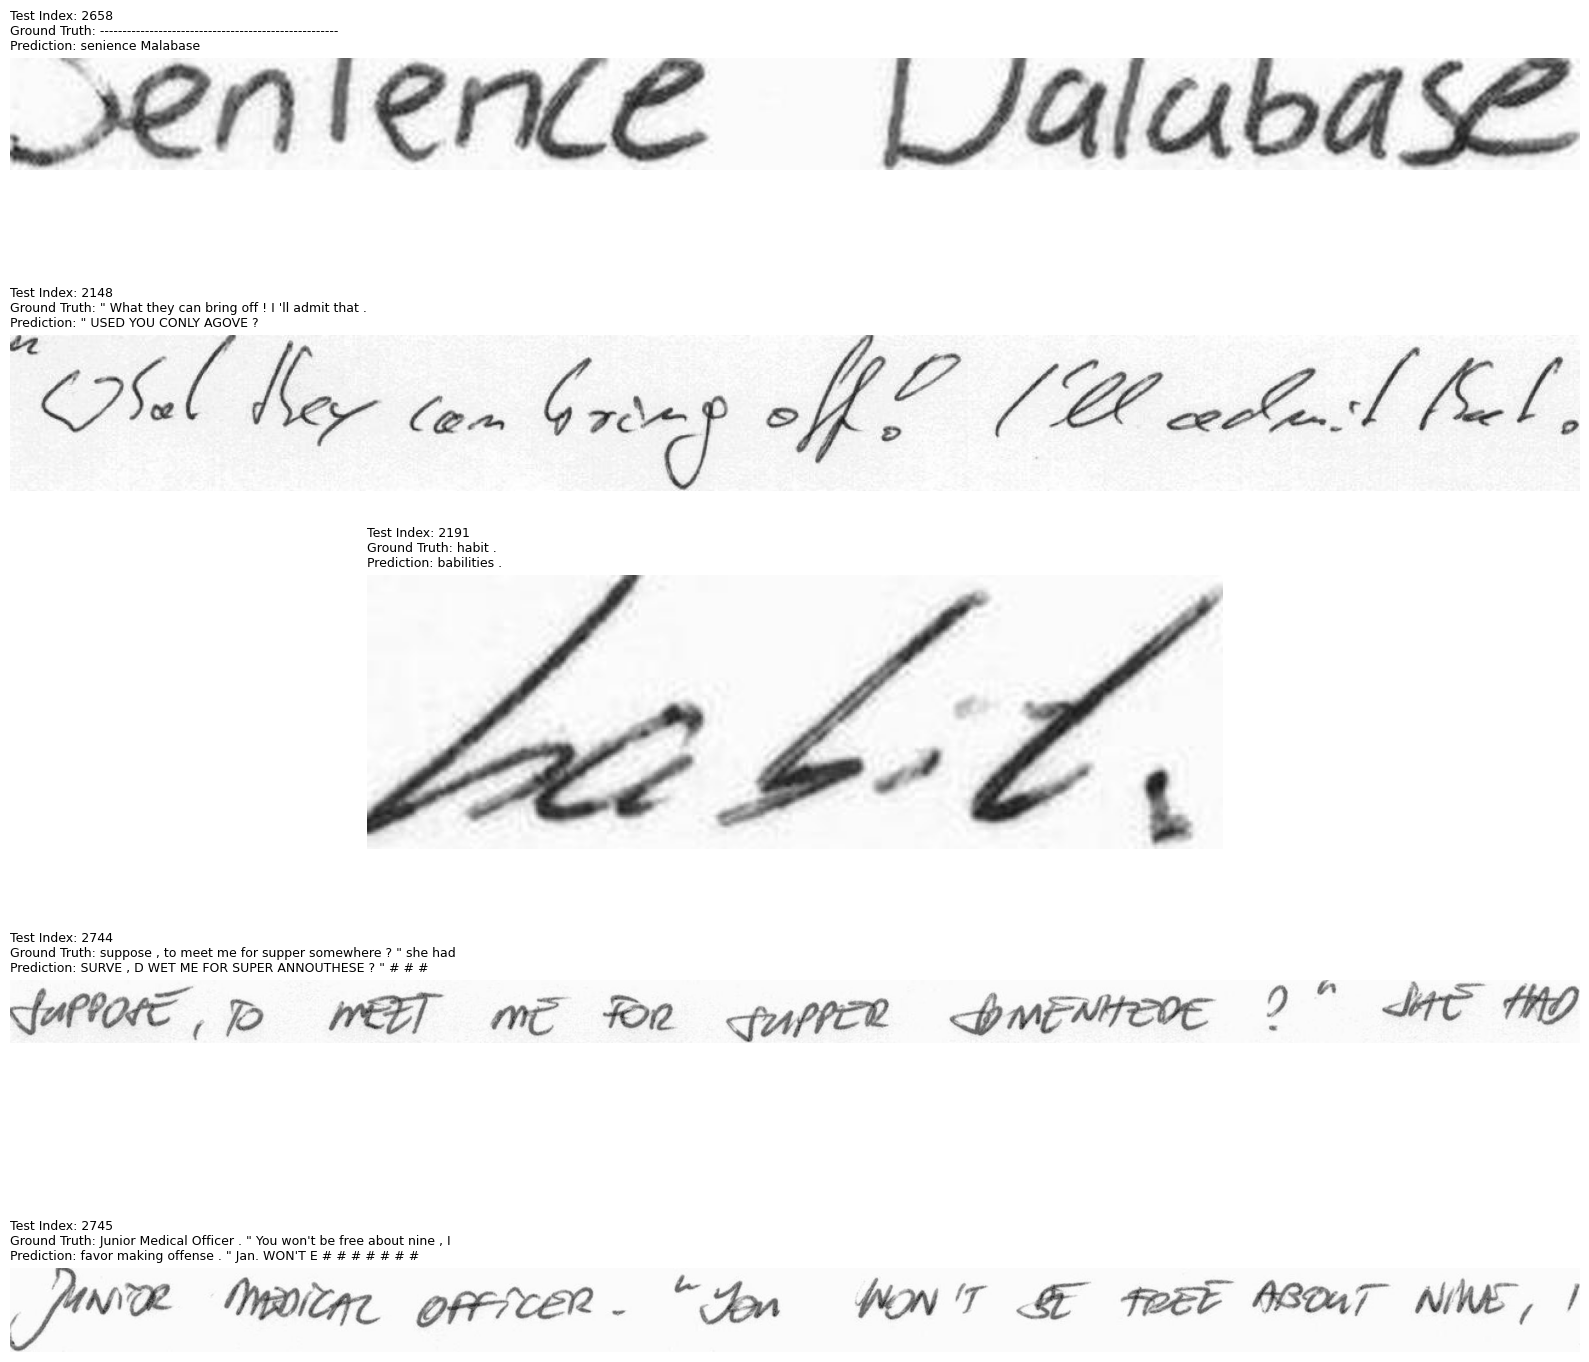

In [114]:
import matplotlib.pyplot as plt
import textwrap

# Select five difficult test samples
selected_indices = [2658, 2148, 2191, 2744, 2745]

fig, axes = plt.subplots(5, 1, figsize=(16, 15))

for ax, idx in zip(axes, selected_indices):

    item = test_data[idx]

    image = item["image"].convert("RGB")
    truth = item["text"]
    prediction = trocr_preds[idx]

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f"Test Index: {idx}\n"
        f"Ground Truth: {textwrap.shorten(truth, width=130)}\n"
        f"Prediction: {textwrap.shorten(prediction, width=130)}",
        fontsize=9,
        loc="left"
    )

plt.tight_layout()
plt.show()

In [115]:
# Verify ground-truth labels for difficult samples

for idx in [2658, 2148, 2191, 2744, 2745]:

    item = test_data[idx]

    print(f"\nSample Index: {idx}")
    print("Ground Truth:", repr(item["text"]))
    print("Prediction:  ", repr(trocr_preds[idx]))
    print("Image Size:  ", item["image"].size)


Sample Index: 2658
Ground Truth: '-----------------------------------------------------'
Prediction:   'senience Malabase'
Image Size:   (1795, 128)

Sample Index: 2148
Ground Truth: '" What they can bring off ! I \'ll admit that .'
Prediction:   '" USED YOU CONLY AGOVE ?'
Image Size:   (1293, 128)

Sample Index: 2191
Ground Truth: 'habit .'
Prediction:   'babilities .'
Image Size:   (400, 128)

Sample Index: 2744
Ground Truth: 'suppose , to meet me for supper somewhere ? " she had'
Prediction:   'SURVE , D WET ME FOR SUPER ANNOUTHESE ? " # # #'
Image Size:   (3191, 128)

Sample Index: 2745
Ground Truth: 'Junior Medical Officer . " You won\'t be free about nine , I'
Prediction:   'favor making offense . " Jan. WON\'T E # # # # # # #'
Image Size:   (2405, 128)


In [116]:
import re

# Find test samples with dash-only labels
suspicious_samples = []

for i, item in enumerate(test_data):

    text = item["text"].strip()

    if re.fullmatch(r"[-–—\s]+", text):
        suspicious_samples.append({
            "index": i,
            "ground_truth": text,
            "prediction": trocr_preds[i],
            "image_size": item["image"].size
        })

print("Dataset Label Inspection")
print("------------------------")
print("Total test samples:", len(test_data))
print("Dash-only labels:", len(suspicious_samples))

for sample in suspicious_samples[:20]:
    print(sample)

Dataset Label Inspection
------------------------
Total test samples: 2915
Dash-only labels: 1
{'index': 2658, 'ground_truth': '-----------------------------------------------------', 'prediction': 'senience Malabase', 'image_size': (1795, 128)}


In [117]:
# Original test metrics
original_cer = corpus_cer(trocr_truths, trocr_preds)

original_word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(trocr_truths, trocr_preds)
)

original_total_words = sum(len(t.split()) for t in trocr_truths)

original_wer = original_word_errors / max(original_total_words, 1)


# Recalculate metrics excluding the invalid annotation
valid_pairs = [
    (truth, prediction)
    for i, (truth, prediction) in enumerate(
        zip(trocr_truths, trocr_preds)
    )
    if i != 2658
]

valid_truths = [x[0] for x in valid_pairs]
valid_preds = [x[1] for x in valid_pairs]

corrected_cer = corpus_cer(valid_truths, valid_preds)

corrected_word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in valid_pairs
)

corrected_total_words = sum(
    len(t.split()) for t in valid_truths
)

corrected_wer = corrected_word_errors / max(corrected_total_words, 1)


print("TrOCR Test Evaluation")
print("---------------------")
print(f"Original CER:  {original_cer:.4f} ({original_cer*100:.2f}%)")
print(f"Original WER:  {original_wer:.4f} ({original_wer*100:.2f}%)")

print("\nAfter excluding sample 2658:")
print(f"Corrected CER: {corrected_cer:.4f} ({corrected_cer*100:.2f}%)")
print(f"Corrected WER: {corrected_wer:.4f} ({corrected_wer*100:.2f}%)")

print("\nValid test samples:", len(valid_pairs))

TrOCR Test Evaluation
---------------------
Original CER:  0.0702 (7.02%)
Original WER:  0.1487 (14.87%)

After excluding sample 2658:
Corrected CER: 0.0698 (6.98%)
Corrected WER: 0.1486 (14.86%)

Valid test samples: 2914


In [118]:
import os
import json
import glob

json_files = glob.glob("experiments/*.json")

print("Available Experiment Files:")
print("---------------------------")

for file_path in sorted(json_files):

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(f"\nFile: {os.path.basename(file_path)}")
    print("Type:", type(data).__name__)

    if isinstance(data, dict):
        print("Keys:", list(data.keys()))

        for key, value in data.items():
            if isinstance(value, (str, int, float, bool)):
                print(f"  {key}: {value}")

    elif isinstance(data, list):
        print("Number of entries:", len(data))
        if data:
            print("First entry:", data[0])

Available Experiment Files:
---------------------------

File: ablation_bilstm_seed0.json
Type: dict
Keys: ['run', 'args', 'params', 'train_time_sec', 'device', 'best_val_cer', 'history']
  run: ablation_bilstm_seed0
  params: 1221264
  train_time_sec: 594.0590331554413
  device: cuda
  best_val_cer: 0.1785663355041118

File: ablation_bilstm_seed1.json
Type: dict
Keys: ['run', 'args', 'params', 'train_time_sec', 'device', 'best_val_cer', 'history']
  run: ablation_bilstm_seed1
  params: 1221264
  train_time_sec: 586.7892591953278
  device: cuda
  best_val_cer: 0.18636212387697865

File: ablation_bilstm_seed2.json
Type: dict
Keys: ['run', 'args', 'params', 'train_time_sec', 'device', 'best_val_cer', 'history']
  run: ablation_bilstm_seed2
  params: 1221264
  train_time_sec: 587.2309882640839
  device: cuda
  best_val_cer: 0.18013500023767648

File: attention_seed0.json
Type: dict
Keys: ['run', 'args', 'params', 'train_time_sec', 'device', 'best_val_cer', 'history']
  run: attention_seed

In [119]:
import json

with open("experiments/trocr_history.json", "r") as f:
    trocr_history = json.load(f)

print("TrOCR Training History")
print("----------------------")

for key, value in trocr_history.items():
    print(f"\n{key}:")
    print(value)

TrOCR Training History
----------------------

epoch_1:
{'train_loss': 0.6179, 'val_cer': 0.0577, 'val_wer': 0.1315}

epoch_2:
{'train_loss': 0.2928, 'val_cer': 0.0653, 'val_wer': 0.1479}

best_epoch:
3

best_val_cer:
0.048557303798070064

epoch_3:
{'train_loss': 0.1263, 'val_cer': 0.048557303798070064, 'val_wer': 0.11404494382022472}

best_val_wer:
0.11404494382022472


In [120]:
import json

files = [
    "experiments/baseline_seed0.json",
    "experiments/ablation_bilstm_seed0.json",
    "experiments/attention_seed0.json",
]

for file_path in files:

    with open(file_path, "r") as f:
        data = json.load(f)

    print("\n" + "=" * 50)
    print("Experiment:", data["run"])
    print("=" * 50)

    print("Parameters:", data["params"])
    print("Training Time:", round(data["train_time_sec"] / 60, 2), "minutes")

    print("\nTraining Arguments:")
    for key, value in data["args"].items():
        print(f"{key}: {value}")


Experiment: baseline_seed0
Parameters: 472464
Training Time: 15.28 minutes

Training Arguments:
model: baseline
epochs: 20
lr: 0.001
batch_size: 8
seed: 0
subset: 0
name: None

Experiment: ablation_bilstm_seed0
Parameters: 1221264
Training Time: 9.9 minutes

Training Arguments:
model: bilstm
epochs: 10
lr: 0.001
batch_size: 4
seed: 0
subset: 0
name: ablation_bilstm_seed0

Experiment: attention_seed0
Parameters: 1484944
Training Time: 9.91 minutes

Training Arguments:
model: attention
epochs: 10
lr: 0.001
batch_size: 4
seed: 0
subset: 0
name: attention_seed0


In [121]:
import os

checkpoint_files = [
    "checkpoints/baseline_seed0.pt",
    "checkpoints/ablation_bilstm_seed0.pt",
    "checkpoints/attention_seed0.pt",
    "checkpoints/trocr_best.pt"
]

print("Model Checkpoint Sizes")
print("----------------------")

for path in checkpoint_files:

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(
            f"{os.path.basename(path)}: "
            f"{size_mb:.2f} MB"
        )
    else:
        print(f"File not found: {path}")

Model Checkpoint Sizes
----------------------
baseline_seed0.pt: 1.81 MB
ablation_bilstm_seed0.pt: 4.67 MB
attention_seed0.pt: 5.68 MB
trocr_best.pt: 1468.33 MB


In [122]:
import inspect

from src.models.baseline import BaselineCNNGRU
from src.models.crnn import CRNNBiLSTM
from src.models.attention import CRNNBiLSTMAttention

print("Model Constructors")
print("------------------")

print("Baseline:", inspect.signature(BaselineCNNGRU))
print("BiLSTM:", inspect.signature(CRNNBiLSTM))
print("Attention:", inspect.signature(CRNNBiLSTMAttention))

Model Constructors
------------------
Baseline: (num_classes, hidden=128)
BiLSTM: (num_classes, hidden_size=128)
Attention: (num_classes, hidden_size=128, num_heads=4)


In [124]:
from src.datasets.iam import get_loaders

data = get_loaders(batch_size=4)

print("Number of returned values:", len(data))

for i, item in enumerate(data):
    print(f"\nReturned item {i}:")
    print("Type:", type(item))

    if isinstance(item, (tuple, list)):
        print("Length:", len(item))

    elif hasattr(item, "dataset"):
        print("Dataset size:", len(item.dataset))

Number of returned values: 3

Returned item 0:
Type: <class 'dict'>

Returned item 1:
Type: <class 'dict'>

Returned item 2:
Type: <class 'dict'>


In [125]:
data = get_loaders(batch_size=4)

for i, item in enumerate(data):

    print(f"\nDictionary {i}")
    print("----------------")

    for key, value in item.items():

        print("Key:", key)
        print("Type:", type(value))

        if hasattr(value, "__len__"):
            print("Length:", len(value))


Dictionary 0
----------------
Key: train
Type: <class 'torch.utils.data.dataloader.DataLoader'>
Length: 1621
Key: validation
Type: <class 'torch.utils.data.dataloader.DataLoader'>
Length: 244
Key: test
Type: <class 'torch.utils.data.dataloader.DataLoader'>
Length: 729

Dictionary 1
----------------
Key:  
Type: <class 'int'>
Key: !
Type: <class 'int'>
Key: "
Type: <class 'int'>
Key: #
Type: <class 'int'>
Key: &
Type: <class 'int'>
Key: '
Type: <class 'int'>
Key: (
Type: <class 'int'>
Key: )
Type: <class 'int'>
Key: *
Type: <class 'int'>
Key: +
Type: <class 'int'>
Key: ,
Type: <class 'int'>
Key: -
Type: <class 'int'>
Key: .
Type: <class 'int'>
Key: /
Type: <class 'int'>
Key: 0
Type: <class 'int'>
Key: 1
Type: <class 'int'>
Key: 2
Type: <class 'int'>
Key: 3
Type: <class 'int'>
Key: 4
Type: <class 'int'>
Key: 5
Type: <class 'int'>
Key: 6
Type: <class 'int'>
Key: 7
Type: <class 'int'>
Key: 8
Type: <class 'int'>
Key: 9
Type: <class 'int'>
Key: :
Type: <class 'int'>
Key: ;
Type: <class 'int

In [128]:
batch = next(iter(test_loader))

print("Batch type:", type(batch))

if isinstance(batch, (tuple, list)):

    print("Number of items:", len(batch))

    for i, item in enumerate(batch):

        print(f"\nItem {i}")
        print("Type:", type(item))

        if hasattr(item, "shape"):
            print("Shape:", item.shape)

        elif isinstance(item, (tuple, list)):
            print("Length:", len(item))
            if len(item) > 0:
                print("First element:", item[0])

else:
    print(batch)

Batch type: <class 'tuple'>
Number of items: 5

Item 0
Type: <class 'torch.Tensor'>
Shape: torch.Size([4, 1, 64, 1750])

Item 1
Type: <class 'torch.Tensor'>
Shape: torch.Size([326])

Item 2
Type: <class 'torch.Tensor'>
Shape: torch.Size([4])

Item 3
Type: <class 'torch.Tensor'>
Shape: torch.Size([4])

Item 4
Type: <class 'list'>
Length: 4
First element: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .


In [129]:
import torch

checkpoint_files = [
    "checkpoints/baseline_seed0.pt",
    "checkpoints/ablation_bilstm_seed0.pt",
    "checkpoints/attention_seed0.pt"
]

for path in checkpoint_files:

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("\n" + "=" * 45)
    print("File:", path)
    print("=" * 45)

    print("Type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))

        if "model" in checkpoint:
            print("Model state keys:",
                  list(checkpoint["model"].keys())[:5])


File: checkpoints/baseline_seed0.pt
Type: <class 'dict'>
Keys: ['model', 'char2idx', 'args']
Model state keys: ['cnn.0.weight', 'cnn.0.bias', 'cnn.1.weight', 'cnn.1.bias', 'cnn.1.running_mean']

File: checkpoints/ablation_bilstm_seed0.pt
Type: <class 'dict'>
Keys: ['model', 'char2idx', 'args']
Model state keys: ['cnn.0.weight', 'cnn.0.bias', 'cnn.1.weight', 'cnn.1.bias', 'cnn.1.running_mean']

File: checkpoints/attention_seed0.pt
Type: <class 'dict'>
Keys: ['model', 'char2idx', 'args']
Model state keys: ['cnn.0.weight', 'cnn.0.bias', 'cnn.1.weight', 'cnn.1.bias', 'cnn.1.running_mean']


In [130]:

import torch
import time

from src.models.baseline import BaselineCNNGRU
from src.models.crnn import CRNNBiLSTM
from src.models.attention import CRNNBiLSTMAttention

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(char2idx) + 1

model_configs = {
    "CNN-GRU": (
        BaselineCNNGRU(num_classes=num_classes),
        "checkpoints/baseline_seed0.pt"
    ),
    "CNN-BiLSTM": (
        CRNNBiLSTM(num_classes=num_classes),
        "checkpoints/ablation_bilstm_seed0.pt"
    ),
    "CNN-BiLSTM-Attention": (
        CRNNBiLSTMAttention(num_classes=num_classes),
        "checkpoints/attention_seed0.pt"
    )
}

# Get one test batch
batch = next(iter(test_loader))
images = batch[0].to(device)

print("Device:", device)
print("Batch shape:", images.shape)

results = {}

for name, (model, checkpoint_path) in model_configs.items():

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model"])
    model = model.to(device)
    model.eval()

    # Warm-up
    with torch.no_grad():
        for _ in range(10):
            _ = model(images)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # Benchmark
    repetitions = 50
    start_time = time.perf_counter()

    with torch.no_grad():
        for _ in range(repetitions):
            _ = model(images)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    avg_batch_time = elapsed / repetitions
    avg_image_time = avg_batch_time / images.size(0)

    results[name] = {
        "batch_ms": avg_batch_time * 1000,
        "image_ms": avg_image_time * 1000
    }

    print(f"\n{name}")
    print(f"Average batch time: {avg_batch_time * 1000:.3f} ms")
    print(f"Average image time: {avg_image_time * 1000:.3f} ms")

print("\nBenchmark completed!")


Device: cuda
Batch shape: torch.Size([4, 1, 64, 1750])

CNN-GRU
Average batch time: 7.266 ms
Average image time: 1.817 ms

CNN-BiLSTM
Average batch time: 9.379 ms
Average image time: 2.345 ms

CNN-BiLSTM-Attention
Average batch time: 10.013 ms
Average image time: 2.503 ms

Benchmark completed!


In [132]:

import time
import torch
import numpy as np
from PIL import Image

trocr_model.eval()

num_samples = 20
sample_images = []

for batch in test_loader:
    images = batch[0]

    for i in range(images.size(0)):
        sample_images.append(images[i])

        if len(sample_images) == num_samples:
            break

    if len(sample_images) == num_samples:
        break

print("Samples collected:", len(sample_images))

inference_times = []

for i, image in enumerate(sample_images):

    # Convert normalized tensor to RGB PIL image
    image = image.squeeze(0).cpu()
    image = ((image + 1) / 2 * 255).clamp(0, 255)
    image = image.byte().numpy()

    pil_image = Image.fromarray(image, mode="L").convert("RGB")

    pixel_values = processor(
        images=pil_image,
        return_tensors="pt"
    ).pixel_values.to(device)

    # Warm-up
    if i == 0:
        with torch.no_grad():
            _ = trocr_model.generate(
                pixel_values,
                max_new_tokens=128,
                num_beams=1
            )

        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        _ = trocr_model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    inference_times.append(elapsed)

    print(f"Sample {i+1}: {elapsed * 1000:.2f} ms")

avg_time = sum(inference_times) / len(inference_times)

print("\nTrOCR Inference Benchmark")
print("-------------------------")
print("Samples:", len(inference_times))
print(f"Average time per image: {avg_time * 1000:.2f} ms")
print(f"Total inference time: {sum(inference_times):.2f} seconds")


Samples collected: 20
Sample 1: 375.26 ms
Sample 2: 201.18 ms
Sample 3: 455.75 ms
Sample 4: 275.33 ms
Sample 5: 359.60 ms
Sample 6: 325.63 ms
Sample 7: 372.08 ms
Sample 8: 313.63 ms
Sample 9: 359.73 ms
Sample 10: 461.40 ms
Sample 11: 255.66 ms
Sample 12: 166.91 ms
Sample 13: 245.96 ms
Sample 14: 166.47 ms
Sample 15: 371.82 ms
Sample 16: 241.55 ms
Sample 17: 273.86 ms
Sample 18: 183.29 ms
Sample 19: 326.92 ms
Sample 20: 254.34 ms

TrOCR Inference Benchmark
-------------------------
Samples: 20
Average time per image: 299.32 ms
Total inference time: 5.99 seconds


In [134]:
%cd /kaggle/working/proj

with open("src/datasets/iam.py", "r", encoding="utf-8") as f:
    print(f.read())

/kaggle/working/proj
import torch
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import numpy as np

IMG_HEIGHT = 64
BLANK = 0  # رقم 0 محجوز لرمز الـ blank بتاع CTC


def build_vocab(texts):
    """يطلع كل الحروف الموجودة في نصوص التدريب ويدّي كل حرف رقم."""
    chars = sorted(set("".join(texts)))
    char2idx = {c: i + 1 for i, c in enumerate(chars)}  # نبدأ من 1
    idx2char = {i: c for c, i in char2idx.items()}
    return char2idx, idx2char


class IAMLines(Dataset):
    def __init__(self, hf_split, char2idx, augment=False):
        self.data = hf_split
        self.char2idx = char2idx
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        item = self.data[i]
        img = item["image"].convert("L")  # رمادي
        w, h = img.size
        new_w = max(8, int(w * IMG_HEIGHT / h))
        img = img.resize((new_w, IMG_HEIGHT))
        x = np.asarray(img, dtype=np.float32) / 255.0
 

In [135]:

%%writefile src/datasets/iam.py

import torch
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import numpy as np
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

IMG_HEIGHT = 64
BLANK = 0

# Training-only augmentation
def apply_augmentation(x):

    # Small random rotation
    angle = float(torch.empty(1).uniform_(-2.0, 2.0).item())
    x = TF.rotate(
        x,
        angle,
        interpolation=InterpolationMode.BILINEAR,
        fill=0
    )

    # Random brightness and contrast
    brightness = float(torch.empty(1).uniform_(0.9, 1.1).item())
    contrast = float(torch.empty(1).uniform_(0.9, 1.1).item())

    x = TF.adjust_brightness(x, brightness)
    x = TF.adjust_contrast(x, contrast)

    # Small Gaussian noise
    if torch.rand(1).item() < 0.3:
        noise = torch.randn_like(x) * 0.015
        x = x + noise

    return x.clamp(0.0, 1.0)


def build_vocab(texts):
    """Build character vocabulary using training texts only."""
    chars = sorted(set("".join(texts)))
    char2idx = {c: i + 1 for i, c in enumerate(chars)}
    idx2char = {i: c for c, i in char2idx.items()}
    return char2idx, idx2char


class IAMLines(Dataset):

    def __init__(self, hf_split, char2idx, augment=False):
        self.data = hf_split
        self.char2idx = char2idx
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):

        item = self.data[i]

        img = item["image"].convert("L")

        w, h = img.size
        new_w = max(8, int(w * IMG_HEIGHT / h))

        img = img.resize((new_w, IMG_HEIGHT))

        x = np.asarray(img, dtype=np.float32) / 255.0
        x = 1.0 - x

        x = torch.from_numpy(x).unsqueeze(0)

        # Apply augmentation only to training images
        if self.augment:
            x = apply_augmentation(x)

        text = item["text"]

        target = torch.tensor([
            self.char2idx[c]
            for c in text
            if c in self.char2idx
        ])

        return x, target, text


def collate(batch):

    images, targets, texts = zip(*batch)

    widths = torch.tensor([im.shape[2] for im in images])

    max_w = int(widths.max())

    padded = torch.zeros(len(images), 1, IMG_HEIGHT, max_w)

    for i, im in enumerate(images):
        padded[i, :, :, :im.shape[2]] = im

    target_lengths = torch.tensor([len(t) for t in targets])

    flat_targets = torch.cat(targets)

    return padded, flat_targets, widths, target_lengths, list(texts)


def get_loaders(batch_size=16):

    ds = load_dataset("Teklia/IAM-line")

    char2idx, idx2char = build_vocab(ds["train"]["text"])

    loaders = {}

    for name in ["train", "validation", "test"]:

        loaders[name] = DataLoader(
            IAMLines(
                ds[name],
                char2idx,
                augment=(name == "train")
            ),
            batch_size=batch_size,
            shuffle=(name == "train"),
            collate_fn=collate,
        )

    return loaders, char2idx, idx2char


if __name__ == "__main__":

    loaders, char2idx, idx2char = get_loaders(batch_size=4)

    print("Vocabulary size:", len(char2idx))

    imgs, targets, widths, tlens, texts = next(iter(loaders["train"]))

    print("Batch shape:", imgs.shape)
    print("Image widths:", widths.tolist())
    print("Text lengths:", tlens.tolist())
    print("First text:", texts[0])


Overwriting src/datasets/iam.py


In [140]:
print("Step 1: Checking imports...")

import torch
print("PyTorch imported")

from src.datasets.iam import get_loaders
print("IAM module imported successfully")

print("Step 2: Checking dataset loading...")

Step 1: Checking imports...
PyTorch imported
IAM module imported successfully
Step 2: Checking dataset loading...


In [141]:

print("Starting dataset loading...")

from datasets import load_dataset

ds = load_dataset("Teklia/IAM-line")

print("Dataset loaded successfully!")

print("Train:", len(ds["train"]))
print("Validation:", len(ds["validation"]))
print("Test:", len(ds["test"]))

print("Building vocabulary...")

from src.datasets.iam import build_vocab

char2idx, idx2char = build_vocab(ds["train"]["text"])

print("Vocabulary size:", len(char2idx))


Starting dataset loading...
Dataset loaded successfully!
Train: 6482
Validation: 976
Test: 2915
Building vocabulary...
Vocabulary size: 79


In [143]:
import importlib
import src.datasets.iam as iam

# Reload the updated module
importlib.reload(iam)

print("Available functions:")
print([name for name in dir(iam) if not name.startswith("_")])

print("\nAugmentation function exists:", hasattr(iam, "apply_augmentation"))

Available functions:
['BLANK', 'DataLoader', 'Dataset', 'IAMLines', 'IMG_HEIGHT', 'InterpolationMode', 'TF', 'apply_augmentation', 'build_vocab', 'collate', 'get_loaders', 'load_dataset', 'np', 'torch', 'transforms']

Augmentation function exists: True


Loading training sample...
Training image: torch.Size([1, 64, 1233])
Training text: put down a resolution on the subject

Loading validation sample...
Validation image: torch.Size([1, 64, 636])
Validation text: It was a splendid interpretation of the


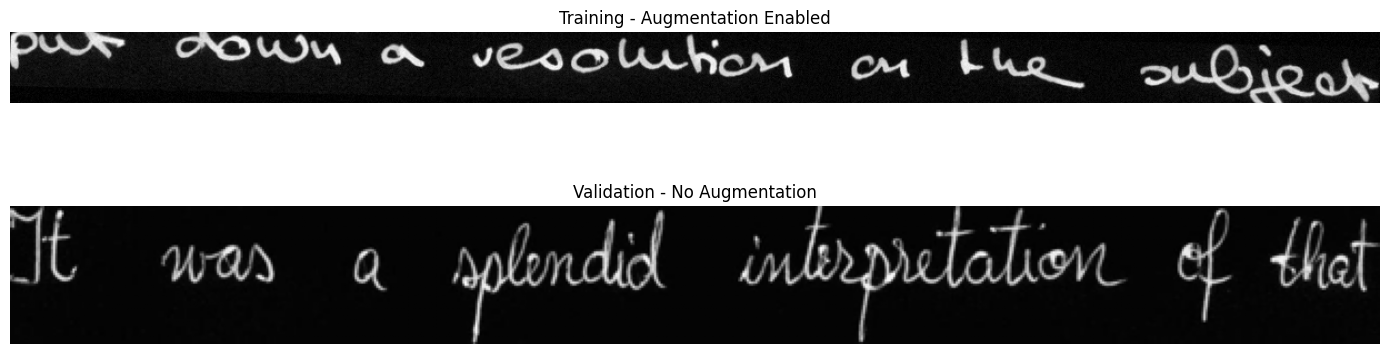


Augmentation test completed!


In [144]:
import matplotlib.pyplot as plt

# Create training and validation datasets
train_dataset = iam.IAMLines(
    ds["train"],
    char2idx,
    augment=True
)

val_dataset = iam.IAMLines(
    ds["validation"],
    char2idx,
    augment=False
)

print("Loading training sample...")
train_image, train_target, train_text = train_dataset[0]

print("Training image:", train_image.shape)
print("Training text:", train_text)

print("\nLoading validation sample...")
val_image, val_target, val_text = val_dataset[0]

print("Validation image:", val_image.shape)
print("Validation text:", val_text)

# Display images
fig, axes = plt.subplots(2, 1, figsize=(14, 5))

axes[0].imshow(train_image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title("Training - Augmentation Enabled")
axes[0].axis("off")

axes[1].imshow(val_image.squeeze(0).numpy(), cmap="gray")
axes[1].set_title("Validation - No Augmentation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("\nAugmentation test completed!")

In [145]:

import torch
from torch.utils.data import DataLoader

# Check that training augmentation produces different images
train_image_1, _, _ = train_dataset[0]
train_image_2, _, _ = train_dataset[0]

train_difference = torch.mean(
    torch.abs(train_image_1 - train_image_2)
).item()

# Check that validation images remain unchanged
val_image_1, _, _ = val_dataset[0]
val_image_2, _, _ = val_dataset[0]

val_difference = torch.mean(
    torch.abs(val_image_1 - val_image_2)
).item()

print("Training image difference:", train_difference)
print("Validation image difference:", val_difference)

# Create DataLoaders using the already loaded dataset
train_loader_aug = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=iam.collate
)

val_loader_aug = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=iam.collate
)

train_batch = next(iter(train_loader_aug))
val_batch = next(iter(val_loader_aug))

print("\nTraining batch shape:", train_batch[0].shape)
print("Validation batch shape:", val_batch[0].shape)

print("\nData strategy verification completed!")


Training image difference: 0.14918015897274017
Validation image difference: 0.0

Training batch shape: torch.Size([4, 1, 64, 1904])
Validation batch shape: torch.Size([4, 1, 64, 677])

Data strategy verification completed!


In [ ]:
%cd /kaggle/working/proj

!python -m src.train --model attention --epochs 10 --batch_size 4 --lr 0.001 --seed 0 --name attention_aug_seed0

/kaggle/working/proj
Device: cuda
Model: attention
Parameters: 1484944
epoch  1 | train loss 2.688 | val CER 0.4523 | val WER 0.8529 | 78s
Best checkpoint saved.
epoch  2 | train loss 1.411 | val CER 0.3241 | val WER 0.7601 | 155s
Best checkpoint saved.
epoch  3 | train loss 1.080 | val CER 0.2536 | val WER 0.6529 | 232s
Best checkpoint saved.
epoch  4 | train loss 0.882 | val CER 0.2109 | val WER 0.5917 | 308s
Best checkpoint saved.
epoch  5 | train loss 0.755 | val CER 0.1992 | val WER 0.5879 | 385s
Best checkpoint saved.
epoch  6 | train loss 0.666 | val CER 0.1750 | val WER 0.5184 | 461s
Best checkpoint saved.
epoch  7 | train loss 0.603 | val CER 0.1626 | val WER 0.4899 | 538s
Best checkpoint saved.
epoch  8 | train loss 0.552 | val CER 0.1509 | val WER 0.4864 | 614s
Best checkpoint saved.


In [1]:
import os
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

checkpoint_path = "/kaggle/working/proj/checkpoints/trocr_best.pt"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size (GB):", round(
        os.path.getsize(checkpoint_path) / (1024**3), 2
    ))

CUDA available: True
GPU: Tesla T4
Checkpoint exists: False


In [2]:
import os

print("Searching for trocr_best.pt...")

search_paths = [
    "/kaggle/working",
    "/kaggle/input"
]

for base_path in search_paths:
    for root, dirs, files in os.walk(base_path):
        if "trocr_best.pt" in files:
            full_path = os.path.join(root, "trocr_best.pt")
            size_gb = os.path.getsize(full_path) / (1024**3)

            print("FOUND!")
            print("Path:", full_path)
            print("Size:", round(size_gb, 2), "GB")

Searching for trocr_best.pt...


In [3]:
import os

print("Kaggle input folders:")
print(os.listdir("/kaggle/input"))

print("\nKaggle working folders:")
print(os.listdir("/kaggle/working"))

Kaggle input folders:
['datasets']

Kaggle working folders:
['.virtual_documents']


In [4]:
import os

base = "/kaggle/input/datasets"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("  " * (level + 1) + file)

datasets/
  mahmoudaboghanem/
    htr-src/
      src/
        ctc_decode.py
        evaluate.py
        train.py


In [9]:
import os

base = "/kaggle/input/datasets/mahmoudaboghanem/htr-src"

for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith((".pt", ".pth", ".bin", ".safetensors")):
            path = os.path.join(root, file)
            size = os.path.getsize(path) / (1024**3)
            print(file, "|", round(size, 2), "GB")

In [1]:
import os

base = "/kaggle/input/htr-project1"

print("Dataset exists:", os.path.exists(base))

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files:
            print("  " * (level + 1) + file)

Dataset exists: False


In [1]:
import os

print("Available Datasets:")
print(os.listdir("/kaggle/input"))

Available Datasets:
['datasets']


In [2]:
import os

base = "/kaggle/input/datasets"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:10]:
            print("  " * (level + 1) + file)

datasets/
  mahmoudaboghanem/
    htr-project1/
      checkpoints/
        ablation_bilstm_seed0.pt
        ablation_bilstm_seed1.pt
        ablation_bilstm_seed2.pt
        attention_aug_seed0.pt
        attention_aug_seed1.pt
        attention_seed0.pt
        attention_seed1.pt
        attention_seed2.pt
        attention_smoke.pt
        baseline_seed0.pt
      experiments/
        ablation_bilstm_seed0.json
        ablation_bilstm_seed1.json
        ablation_bilstm_seed2.json
        attention_aug_seed0.json
        attention_aug_seed1.json
        attention_seed0.json
        attention_seed1.json
        attention_seed2.json
        attention_smoke.json
        baseline_seed0.json
      src/
        ctc_decode.py
        evaluate.py
        test.py
        train.py


In [3]:
import os

checkpoint_dir = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints"

print("All checkpoints:")

for file in sorted(os.listdir(checkpoint_dir)):
    path = os.path.join(checkpoint_dir, file)
    size = os.path.getsize(path) / (1024**3)

    print(f"{file} | {size:.3f} GB")

All checkpoints:
ablation_bilstm_seed0.pt | 0.005 GB
ablation_bilstm_seed1.pt | 0.005 GB
ablation_bilstm_seed2.pt | 0.005 GB
attention_aug_seed0.pt | 0.006 GB
attention_aug_seed1.pt | 0.006 GB
attention_seed0.pt | 0.006 GB
attention_seed1.pt | 0.006 GB
attention_seed2.pt | 0.006 GB
attention_smoke.pt | 0.006 GB
baseline_seed0.pt | 0.002 GB
bilstm_seed0.pt | 0.005 GB
bilstm_smoke_test.pt | 0.005 GB
trocr_best.pt | 1.434 GB
trocr_processor | 0.000 GB


In [4]:
import os
import torch

base = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1"

checkpoint_path = os.path.join(
    base, "checkpoints", "trocr_best.pt"
)

processor_path = os.path.join(
    base, "checkpoints", "trocr_processor"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Processor exists:", os.path.isdir(processor_path))

print("\nProcessor files:")
print(os.listdir(processor_path))

print("\nLoading checkpoint information...")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
print("Number of parameters:", len(checkpoint))

print("\nFirst 10 keys:")
for key in list(checkpoint.keys())[:10]:
    print(key, checkpoint[key].shape)

Checkpoint exists: True
Processor exists: True

Processor files:
['processor_config.json', 'tokenizer.json', 'tokenizer_config.json']

Loading checkpoint information...
Checkpoint type: <class 'collections.OrderedDict'>
Number of parameters: 478

First 10 keys:
encoder.embeddings.cls_token torch.Size([1, 1, 768])
encoder.embeddings.position_embeddings torch.Size([1, 577, 768])
encoder.embeddings.patch_embeddings.projection.weight torch.Size([768, 3, 16, 16])
encoder.embeddings.patch_embeddings.projection.bias torch.Size([768])
encoder.layers.0.attention.q_proj.weight torch.Size([768, 768])
encoder.layers.0.attention.k_proj.weight torch.Size([768, 768])
encoder.layers.0.attention.v_proj.weight torch.Size([768, 768])
encoder.layers.0.attention.o_proj.weight torch.Size([768, 768])
encoder.layers.0.attention.o_proj.bias torch.Size([768])
encoder.layers.0.layernorm_before.weight torch.Size([768])


In [5]:
import json
import os
import transformers

processor_path = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints/trocr_processor"

print("Transformers version:", transformers.__version__)

for filename in ["processor_config.json", "tokenizer_config.json"]:
    path = os.path.join(processor_path, filename)

    print(f"\n===== {filename} =====")

    with open(path, "r", encoding="utf-8") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2)[:3000])

Transformers version: 5.20.2

===== processor_config.json =====
{
  "image_processor": {
    "do_normalize": true,
    "do_rescale": true,
    "do_resize": true,
    "image_mean": [
      0.5,
      0.5,
      0.5
    ],
    "image_processor_type": "ViTImageProcessor",
    "image_std": [
      0.5,
      0.5,
      0.5
    ],
    "resample": 2,
    "rescale_factor": 0.00392156862745098,
    "size": {
      "height": 384,
      "width": 384
    }
  },
  "processor_class": "TrOCRProcessor"
}

===== tokenizer_config.json =====
{
  "add_prefix_space": false,
  "backend": "tokenizers",
  "bos_token": "<s>",
  "cls_token": "<s>",
  "eos_token": "</s>",
  "errors": "replace",
  "is_local": false,
  "local_files_only": false,
  "mask_token": "<mask>",
  "model_max_length": 512,
  "pad_token": "<pad>",
  "processor_class": "TrOCRProcessor",
  "sep_token": "</s>",
  "tokenizer_class": "RobertaTokenizer",
  "trim_offsets": true,
  "unk_token": "<unk>"
}


In [6]:
import json
import os
import transformers

processor_path = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints/trocr_processor"

print("Transformers version:", transformers.__version__)

for filename in ["processor_config.json", "tokenizer_config.json"]:
    path = os.path.join(processor_path, filename)

    print(f"\n===== {filename} =====")

    with open(path, "r", encoding="utf-8") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2)[:3000])

Transformers version: 5.20.2

===== processor_config.json =====
{
  "image_processor": {
    "do_normalize": true,
    "do_rescale": true,
    "do_resize": true,
    "image_mean": [
      0.5,
      0.5,
      0.5
    ],
    "image_processor_type": "ViTImageProcessor",
    "image_std": [
      0.5,
      0.5,
      0.5
    ],
    "resample": 2,
    "rescale_factor": 0.00392156862745098,
    "size": {
      "height": 384,
      "width": 384
    }
  },
  "processor_class": "TrOCRProcessor"
}

===== tokenizer_config.json =====
{
  "add_prefix_space": false,
  "backend": "tokenizers",
  "bos_token": "<s>",
  "cls_token": "<s>",
  "eos_token": "</s>",
  "errors": "replace",
  "is_local": false,
  "local_files_only": false,
  "mask_token": "<mask>",
  "model_max_length": 512,
  "pad_token": "<pad>",
  "processor_class": "TrOCRProcessor",
  "sep_token": "</s>",
  "tokenizer_class": "RobertaTokenizer",
  "trim_offsets": true,
  "unk_token": "<unk>"
}


In [7]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# Paths
checkpoint_path = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints/trocr_best.pt"
processor_path = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints/trocr_processor"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Loading processor...")

processor = TrOCRProcessor.from_pretrained(
    processor_path,
    use_fast=True
)

print("Processor loaded successfully!")

print("\nLoading base TrOCR model...")

model = VisionEncoderDecoderModel.from_pretrained(
    "microsoft/trocr-base-stage1"
)

print("Base model loaded successfully!")

print("\nLoading fine-tuned checkpoint...")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

load_result = model.load_state_dict(checkpoint, strict=True)

print("Checkpoint loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

model.to(device)
model.eval()

print("\n" + "=" * 50)
print("TrOCR MODEL READY")
print("=" * 50)
print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Processor:", type(processor).__name__)
print("Model mode:", "Evaluation" if not model.training else "Training")

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Device: cuda
Loading processor...
Processor loaded successfully!

Loading base TrOCR model...


config.json:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.54GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/476 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-stage1
Key                                                 | Status     | 
----------------------------------------------------+------------+-
decoder.model.decoder.embed_positions._float_tensor | UNEXPECTED | 
encoder.pooler.dense.bias                           | MISSING    | 
encoder.pooler.dense.weight                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Base model loaded successfully!

Loading fine-tuned checkpoint...
Checkpoint loaded successfully!
Missing keys: []
Unexpected keys: []

TrOCR MODEL READY
Device: cuda
Model parameters: 384864768
Processor: TrOCRProcessor
Model mode: Evaluation


In [8]:
from pathlib import Path

project_path = Path(
    "/kaggle/input/datasets/mahmoudaboghanem/htr-project1"
)

files_to_inspect = [
    project_path / "src" / "test.py",
    project_path / "src" / "datasets" / "iam.py"
]

for file_path in files_to_inspect:
    print("\n" + "=" * 80)
    print("FILE:", file_path)
    print("=" * 80)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")


FILE: /kaggle/input/datasets/mahmoudaboghanem/htr-project1/src/test.py

import torch
from src.datasets.iam import get_loaders
from src.ctc_decode import greedy_decode
from src.evaluate import corpus_cer, edit_distance
from src.models.baseline import BaselineCNNGRU, output_lengths


def main():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)

    loaders, char2idx, idx2char = get_loaders(batch_size=8)

    checkpoint = torch.load(
        "checkpoints/baseline_seed0.pt",
        map_location=device,
        weights_only=False
    )

    model = BaselineCNNGRU(len(char2idx) + 1).to(device)
    model.load_state_dict(checkpoint["model"])
    model.eval()

    truths, predictions = [], []

    with torch.no_grad():
        for imgs, targets, widths, tlens, texts in loaders["test"]:
            log_probs = model(imgs.to(device)).cpu()
            batch_preds = greedy_decode(
                log_probs, output_lengths(widths), idx2char
            )
  

In [9]:
from datasets import load_dataset
from PIL import Image
import torch

print("Loading IAM dataset...")

ds = load_dataset("Teklia/IAM-line")

test_data = ds["test"]

print("\nDataset loaded successfully!")
print("Train samples:", len(ds["train"]))
print("Validation samples:", len(ds["validation"]))
print("Test samples:", len(test_data))

# Inspect first test sample
sample = test_data[0]
image = sample["image"].convert("RGB")
text = sample["text"]

print("\nFirst test sample:")
print("Ground truth:", repr(text))
print("Original image size:", image.size)
print("Image mode:", image.mode)

# Process image using TrOCR processor
pixel_values = processor(
    images=image,
    return_tensors="pt"
).pixel_values

print("\nProcessor output:")
print("Shape:", pixel_values.shape)
print("Data type:", pixel_values.dtype)
print("Minimum:", pixel_values.min().item())
print("Maximum:", pixel_values.max().item())

print("\nTest data preparation check completed!")

Loading IAM dataset...


README.md:   0%|          | 0.00/2.14k [00:00<?, ?B/s]

data/train.parquet: reconstructing file:   0%|          |  0.00B /  167MB            

data/train.parquet: downloading bytes:           |  0.00B            

data/validation.parquet: reconstructing file:   0%|          |  0.00B / 24.7MB            

data/validation.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/6482 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/976 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2915 [00:00<?, ? examples/s]


Dataset loaded successfully!
Train samples: 6482
Validation samples: 976
Test samples: 2915

First test sample:
Ground truth: 'assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .'
Original image size: (2611, 128)
Image mode: RGB

Processor output:
Shape: torch.Size([1, 3, 384, 384])
Data type: torch.float32
Minimum: -0.7098039388656616
Maximum: 0.9921568632125854

Test data preparation check completed!


In [10]:
from pathlib import Path

evaluate_path = Path(
    "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/src/evaluate.py"
)

print(evaluate_path.read_text(encoding="utf-8"))

def edit_distance(a, b):
    """أقل عدد عمليات (استبدال/حذف/إضافة) لتحويل a إلى b.
    a و b ممكن يكونوا نصوص (للحروف) أو lists من كلمات."""
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        dp[i][0] = i
    for j in range(len(b) + 1):
        dp[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i][j] = min(
                dp[i - 1][j] + 1,         # حذف
                dp[i][j - 1] + 1,         # إضافة
                dp[i - 1][j - 1] + cost,  # استبدال (أو تطابق)
            )
    return dp[len(a)][len(b)]


def cer(truth, pred):
    """Character Error Rate لجملة واحدة."""
    if len(truth) == 0:
        return 0.0 if len(pred) == 0 else 1.0
    return edit_distance(truth, pred) / len(truth)


def wer(truth, pred):
    """Word Error Rate: نفس الفكرة لكن على الكلمات."""
    t, p = truth.split(), pred.split()
    if len(t) == 0:
        re

In [13]:
import torch

print("Checking decoder positional embeddings...")

pos_module = model.decoder.model.decoder.embed_positions

print("Before fix:")
print("Weights device:", pos_module.weights.device)

# Initialize positional embeddings
with torch.no_grad():
    new_weights = pos_module.get_embedding(
        1026,
        1024,
        pos_module.padding_idx
    )

    pos_module.weights = new_weights.to(device)

print("\nAfter fix:")
print("Weights device:", pos_module.weights.device)
print("Weights shape:", pos_module.weights.shape)

# Verify the model is still in evaluation mode
model.eval()

print("\nPositional embeddings initialized successfully!")

Checking decoder positional embeddings...
Before fix:
Weights device: meta

After fix:
Weights device: cuda:0
Weights shape: torch.Size([1026, 1024])

Positional embeddings initialized successfully!


In [14]:
import torch

# Get first 4 test samples
batch = test_data[:4]

images = [
    img.convert("RGB")
    for img in batch["image"]
]

pixel_values = processor(
    images=images,
    return_tensors="pt"
).pixel_values.to(device)

print("Input shape:", pixel_values.shape)

model.eval()

with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        generated_ids = model.generate(
            pixel_values,
            max_new_tokens=128,
            num_beams=1
        )

test_predictions = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)

print("\nFirst batch predictions:")
for i in range(4):
    print(f"\nSample {i + 1}")
    print("Ground Truth:", batch["text"][i])
    print("Prediction:  ", test_predictions[i])

print("\nGenerated IDs shape:", generated_ids.shape)
print("\nFirst batch test successful!")

Input shape: torch.Size([4, 3, 384, 384])

First batch predictions:

Sample 1
Ground Truth: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Prediction:   assurances " Bella Bella " Marketplace ! A lively song that danger tempo mid-way .

Sample 2
Ground Truth: I don't think he will storm the charts with this one , but it 's a good start .
Prediction:   I don't think he will show the charts with this one , but it 's a good start .

Sample 3
Ground Truth: CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Prediction:   CHRIS CHARLES , 39 , who lives in Stockholm-on - Fees , is an accountant .

Sample 4
Ground Truth: Become a success with a disc and hey presto ! You 're a star ... . Rolly sings with
Prediction:   Become a success with a disc and key person . You 're a star ... . Rally sings with

Generated IDs shape: torch.Size([4, 23])

First batch test successful!


In [15]:
import torch
import json
import time
from tqdm.auto import tqdm

# ============================================================
# 1. EDIT DISTANCE
# ============================================================

def edit_distance(a, b):
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]

    for i in range(len(a) + 1):
        dp[i][0] = i

    for j in range(len(b) + 1):
        dp[0][j] = j

    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + cost
            )

    return dp[len(a)][len(b)]


# ============================================================
# 2. EVALUATION SETTINGS
# ============================================================

BATCH_SIZE = 4
MAX_NEW_TOKENS = 128

model.eval()

truths = []
predictions = []

total_samples = len(test_data)

print("=" * 60)
print("TrOCR TEST EVALUATION")
print("=" * 60)

print("Device:", device)
print("Test samples:", total_samples)
print("Batch size:", BATCH_SIZE)
print("Max new tokens:", MAX_NEW_TOKENS)

# ============================================================
# 3. FIX POSITIONAL EMBEDDINGS
# ============================================================

pos_module = model.decoder.model.decoder.embed_positions

if pos_module.weights.device.type == "meta":

    print("\nInitializing positional embeddings...")

    with torch.no_grad():
        new_weights = pos_module.get_embedding(
            1026,
            1024,
            pos_module.padding_idx
        )

        pos_module.weights = new_weights.to(device)

print("Positional embeddings device:", pos_module.weights.device)

# ============================================================
# 4. RUN TEST INFERENCE
# ============================================================

start_time = time.time()

for start in tqdm(range(0, total_samples, BATCH_SIZE)):

    end = min(start + BATCH_SIZE, total_samples)

    batch = test_data[start:end]

    images = [
        img.convert("RGB")
        for img in batch["image"]
    ]

    batch_texts = batch["text"]

    # Preprocess images
    pixel_values = processor(
        images=images,
        return_tensors="pt"
    ).pixel_values.to(device)

    # Generate predictions
    with torch.inference_mode():

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            generated_ids = model.generate(
                pixel_values,
                max_new_tokens=MAX_NEW_TOKENS,
                num_beams=1
            )

    # Decode predictions
    batch_predictions = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    truths.extend(batch_texts)
    predictions.extend(batch_predictions)

    del pixel_values, generated_ids

# ============================================================
# 5. CALCULATE CER
# ============================================================

total_char_errors = sum(
    edit_distance(t, p)
    for t, p in zip(truths, predictions)
)

total_characters = sum(
    len(t)
    for t in truths
)

test_cer = (
    total_char_errors / total_characters
    if total_characters > 0 else 0.0
)

# ============================================================
# 6. CALCULATE WER
# ============================================================

total_word_errors = sum(
    edit_distance(t.split(), p.split())
    for t, p in zip(truths, predictions)
)

total_words = sum(
    len(t.split())
    for t in truths
)

test_wer = (
    total_word_errors / total_words
    if total_words > 0 else 0.0
)

# ============================================================
# 7. COMPUTATIONAL TIME
# ============================================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.time() - start_time

average_time = total_time / len(truths)

# ============================================================
# 8. SAVE PREDICTIONS
# ============================================================

results = [
    {
        "index": i,
        "ground_truth": truth,
        "prediction": prediction
    }
    for i, (truth, prediction) in enumerate(
        zip(truths, predictions)
    )
]

output_path = "/kaggle/working/trocr_test_predictions.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        results,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 9. PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 60)
print("TrOCR FINAL TEST RESULTS")
print("=" * 60)

print("Test samples:", len(truths))

print("\nCharacter Evaluation:")
print("Total character errors:", total_char_errors)
print("Total characters:", total_characters)
print(f"Test CER: {test_cer:.4f} ({test_cer * 100:.2f}%)")

print("\nWord Evaluation:")
print("Total word errors:", total_word_errors)
print("Total words:", total_words)
print(f"Test WER: {test_wer:.4f} ({test_wer * 100:.2f}%)")

print("\nComputational Cost:")
print(f"Total evaluation time: {total_time / 60:.2f} minutes")
print(f"Average inference time: {average_time * 1000:.2f} ms/image")

print("\nFirst 10 Predictions:")

for i in range(min(10, len(truths))):

    print(f"\nSample {i + 1}")
    print("Ground Truth:", truths[i])
    print("Prediction:  ", predictions[i])

print("\nPredictions saved to:")
print(output_path)

print("=" * 60)
print("TEST EVALUATION COMPLETED")
print("=" * 60)

TrOCR TEST EVALUATION
Device: cuda
Test samples: 2915
Batch size: 4
Max new tokens: 128
Positional embeddings device: cuda:0


  0%|          | 0/729 [00:00<?, ?it/s]


TrOCR FINAL TEST RESULTS
Test samples: 2915

Character Evaluation:
Total character errors: 8708
Total characters: 125615
Test CER: 0.0693 (6.93%)

Word Evaluation:
Total word errors: 3827
Total words: 25931
Test WER: 0.1476 (14.76%)

Computational Cost:
Total evaluation time: 4.14 minutes
Average inference time: 85.15 ms/image

First 10 Predictions:

Sample 1
Ground Truth: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .
Prediction:   assurances " Bella Bella " Marketplace ! A lively song that danger tempo mid-way .

Sample 2
Ground Truth: I don't think he will storm the charts with this one , but it 's a good start .
Prediction:   I don't think he will show the charts with this one , but it 's a good start .

Sample 3
Ground Truth: CHRIS CHARLES , 39 , who lives in Stockton-on-Tees , is an accountant .
Prediction:   CHRIS CHARLES , 39 , who lives in Stockholm-on - Fees , is an accountant .

Sample 4
Ground Truth: Become a success with a di

In [ ]:
from IPython.display import display
from PIL import Image
import ipywidgets as widgets
import torch

# Upload image
uploader = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

display(uploader)

Original image size: (2048, 768)


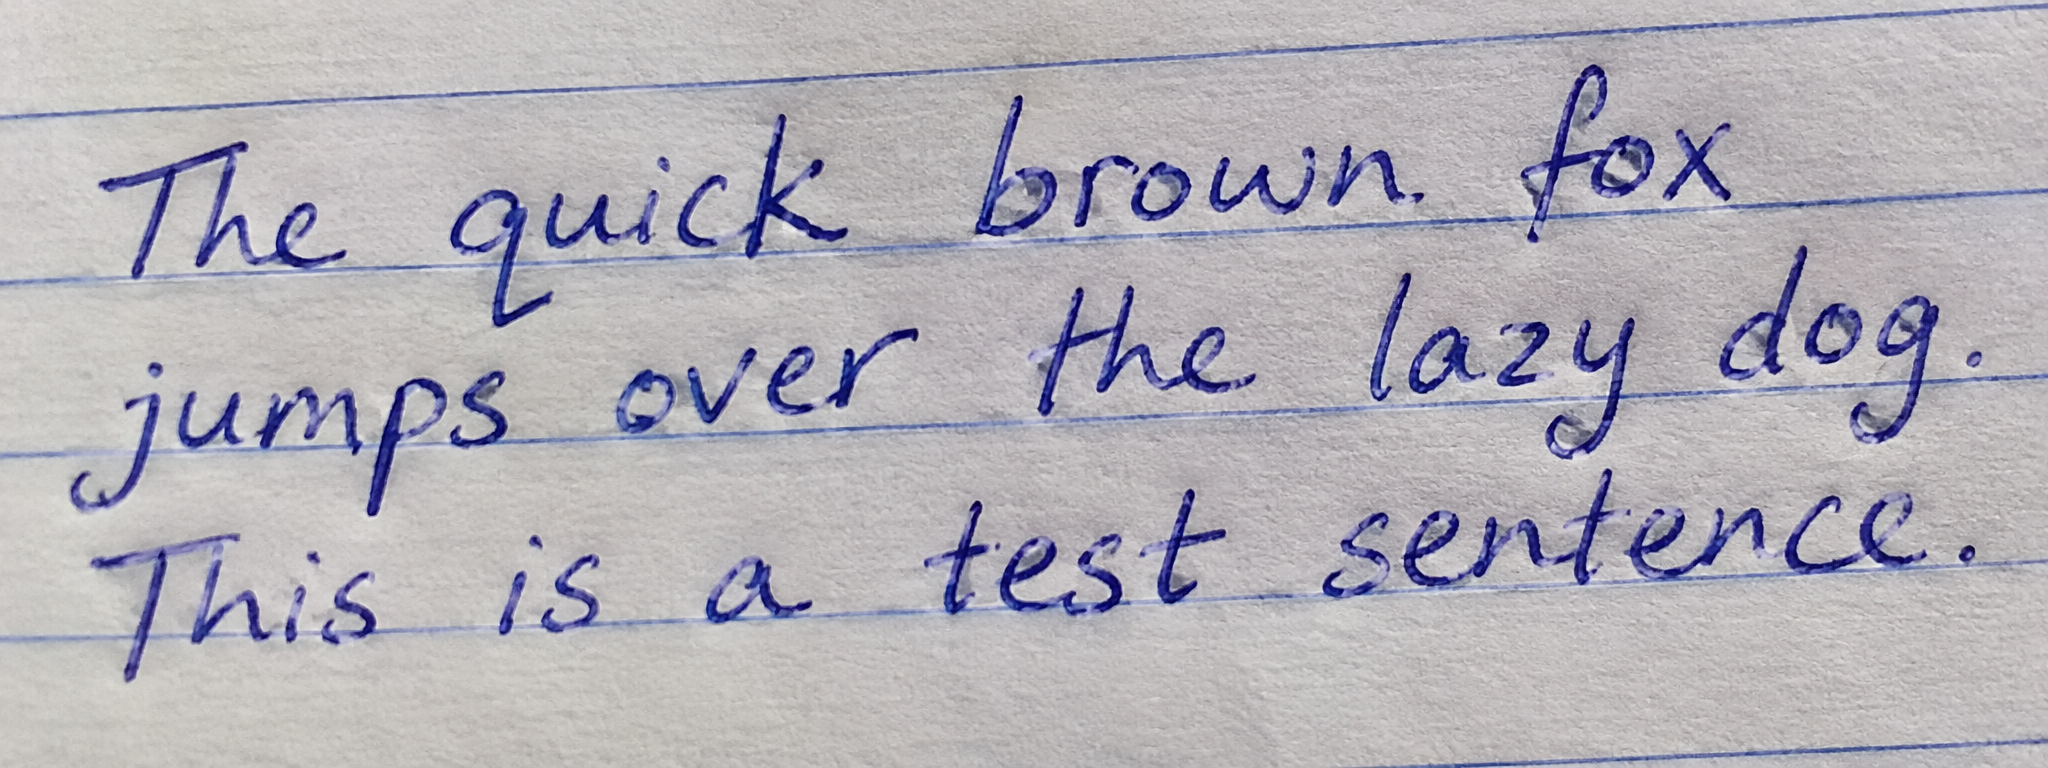


TrOCR Predictions:

Line 1:


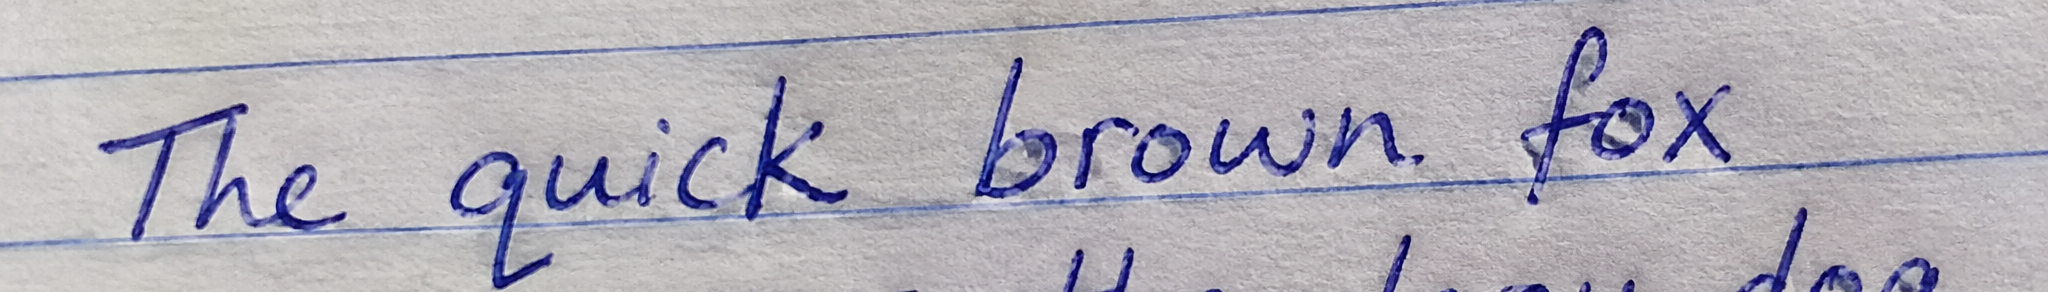

Prediction: The quick brown . Box
------------------------------------------------------------

Line 2:


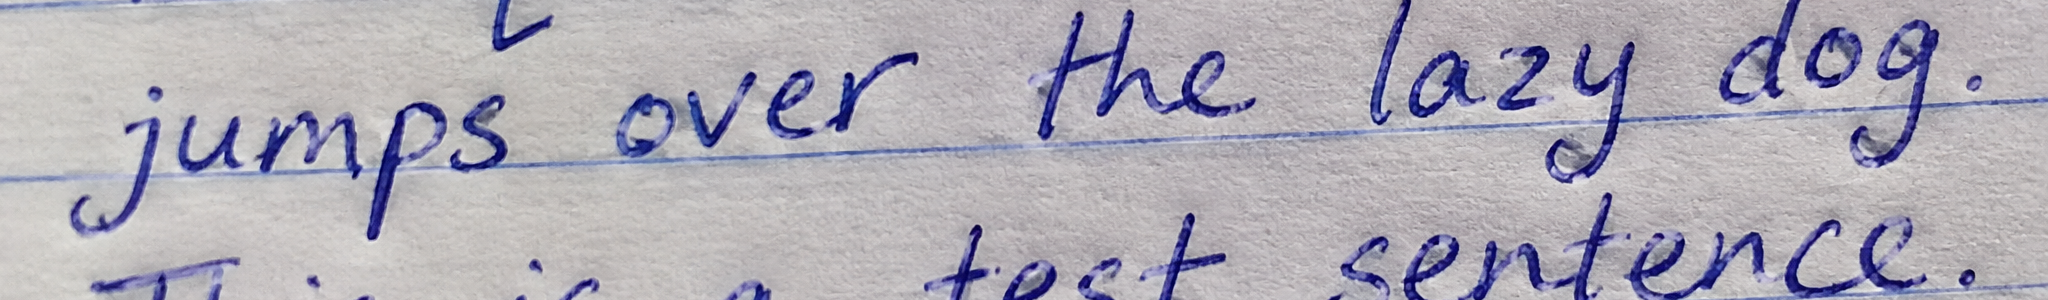

Prediction: jumps over the lasty dog .
------------------------------------------------------------

Line 3:


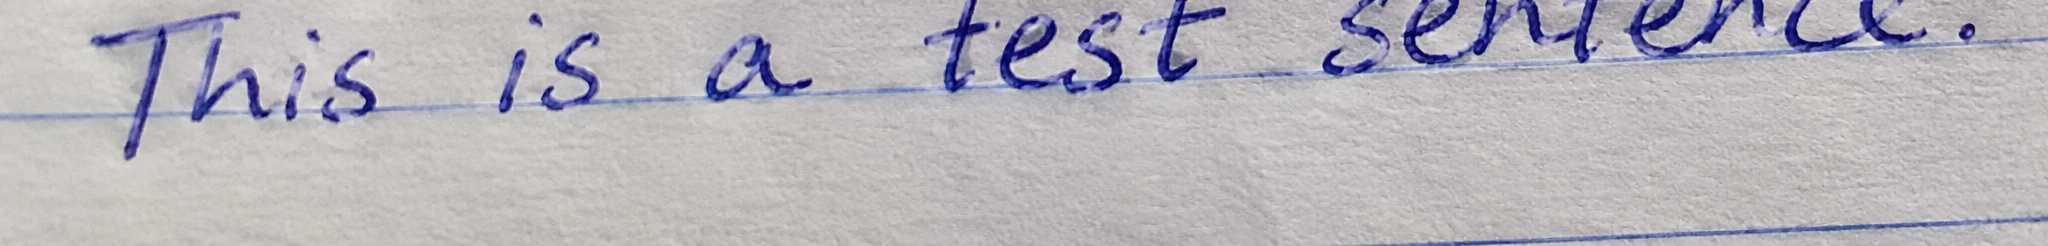

Prediction: This is a test sentence .
------------------------------------------------------------


In [24]:
from PIL import Image
from IPython.display import display
import torch

# Image path
image_path = "/kaggle/input/datasets/mahmoudaboghanem/test-img/eb3d74b8-9bbc-4944-9efb-70e58d24c78a.png"

# Load image
image = Image.open(image_path).convert("RGB")

print("Original image size:", image.size)
display(image)

# Crop the three handwritten lines
w, h = image.size

line_crops = [
    image.crop((0, int(h * 0.05), w, int(h * 0.43))),
    image.crop((0, int(h * 0.36), w, int(h * 0.75))),
    image.crop((0, int(h * 0.68), w, h))
]

# Get model device
device = next(model.parameters()).device

print("\nTrOCR Predictions:")
print("=" * 60)

for i, line_image in enumerate(line_crops, 1):

    print(f"\nLine {i}:")
    display(line_image)

    pixel_values = processor(
        images=line_image,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.no_grad():
        if device.type == "cuda":
            with torch.autocast("cuda", dtype=torch.float16):
                generated_ids = model.generate(
                    pixel_values,
                    max_new_tokens=128,
                    num_beams=1
                )
        else:
            generated_ids = model.generate(
                pixel_values,
                max_new_tokens=128,
                num_beams=1
            )

    prediction = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    print("Prediction:", prediction)
    print("-" * 60)

In [2]:
import os

checkpoint_dir = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1/checkpoints"

print("Available checkpoints:\n")

for file in os.listdir(checkpoint_dir):
    print(file)

Available checkpoints:

ablation_bilstm_seed0.pt
ablation_bilstm_seed1.pt
ablation_bilstm_seed2.pt
attention_aug_seed0.pt
attention_aug_seed1.pt
attention_seed0.pt
attention_seed1.pt
attention_seed2.pt
attention_smoke.pt
baseline_seed0.pt
bilstm_seed0.pt
bilstm_smoke_test.pt
trocr_best.pt
trocr_processor


In [3]:
import os

project_dir = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1"

for root, dirs, files in os.walk(project_dir):
    level = root.replace(project_dir, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

htr-project1/
    checkpoints/
        ablation_bilstm_seed0.pt
        ablation_bilstm_seed1.pt
        ablation_bilstm_seed2.pt
        attention_aug_seed0.pt
        attention_aug_seed1.pt
        attention_seed0.pt
        attention_seed1.pt
        attention_seed2.pt
        attention_smoke.pt
        baseline_seed0.pt
        bilstm_seed0.pt
        bilstm_smoke_test.pt
        trocr_best.pt
        trocr_processor/
            processor_config.json
            tokenizer.json
            tokenizer_config.json
    experiments/
        ablation_bilstm_seed0.json
        ablation_bilstm_seed1.json
        ablation_bilstm_seed2.json
        attention_aug_seed0.json
        attention_aug_seed1.json
        attention_seed0.json
        attention_seed1.json
        attention_seed2.json
        attention_smoke.json
        baseline_seed0.json
        bilstm_seed0.json
        bilstm_smoke_test.json
        trocr_corrected_seed0.json
        trocr_history.json
        trocr_test_predictio

In [5]:
import sys
import os
import json

PROJECT_DIR = "/kaggle/input/datasets/mahmoudaboghanem/htr-project1"

# Add project directory to Python path
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from datasets import load_dataset
from src.datasets.iam import build_vocab

print("Source code imported successfully!")

# Load IAM dataset
ds = load_dataset("Teklia/IAM-line")

# Build exact training vocabulary
char2idx, idx2char = build_vocab(ds["train"]["text"])

# Create export directory
os.makedirs("/kaggle/working/htr_export", exist_ok=True)

vocab = {
    "char2idx": char2idx,
    "idx2char": {str(k): v for k, v in idx2char.items()}
}

vocab_path = "/kaggle/working/htr_export/vocab.json"

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)

print("\nVocabulary saved successfully!")
print("Vocabulary size:", len(char2idx))
print("Number of classes:", len(char2idx) + 1)
print("Saved at:", vocab_path)

Source code imported successfully!


README.md:   0%|          | 0.00/2.14k [00:00<?, ?B/s]

data/train.parquet: reconstructing file:   0%|          |  0.00B /  167MB            

data/train.parquet: downloading bytes:           |  0.00B            

data/validation.parquet: reconstructing file:   0%|          |  0.00B / 24.7MB            

data/validation.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/6482 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/976 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2915 [00:00<?, ? examples/s]


Vocabulary saved successfully!
Vocabulary size: 79
Number of classes: 80
Saved at: /kaggle/working/htr_export/vocab.json


In [6]:
import os

for root, dirs, files in os.walk("/kaggle/working/htr_export"):
    print(root)
    for file in files:
        print("   ", file)

/kaggle/working/htr_export
    vocab.json


In [8]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/htr_export/vocab.json"))

/kaggle/working/htr_export/vocab.json